# 5G-NIDD GBDT Evaluation + Comparison Notebook

This notebook evaluates and compares multiple trained classifiers (XGBoost, LightGBM, CatBoost) on the labeled test files named `test_input_with_label.csv`.

It does all of the following in one place:

## Per run / per model
- loads model configs from `classifier_training_gbdt/training_summaries_all.json`
- checks that required model files exist
- loads each mapped labeled test file
- aligns test features to the exact order expected by the trained model
- generates predictions and class probabilities
- computes detailed metrics:
  - accuracy
  - balanced accuracy
  - precision / recall / F1 (macro, weighted, micro)
  - MCC
  - Cohen's kappa
  - attack-only recall / attack-only F1
  - benign false positive rate (if `Benign` exists)
- saves:
  - predictions CSV
  - per-run global metrics JSON and CSV
  - per-run per-class metrics CSV
  - confusion matrix CSV
  - normalized confusion matrix CSV
  - confusion matrix heatmap PNG

## Cross-model comparison
- builds a global summary table across all evaluated models
- builds a per-class comparison table across all evaluated models
- creates quick comparison plots:
  - accuracy / balanced accuracy / macro F1 / weighted F1
  - MCC / Cohen's kappa
  - attack-only recall / attack-only F1
  - per-class recall heatmap
  - per-class F1 heatmap
  - global metrics heatmap
- exports comparison tables as CSV

## Output folder
All outputs are written under:

`outputs_mapped_batch/`


In [15]:
# !pip install -U pandas numpy scikit-learn xgboost lightgbm catboost matplotlib openpyxl

import os
import json
from pathlib import Path
from typing import Dict, List, Optional, Tuple

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    matthews_corrcoef,
    cohen_kappa_score,
)

## Load training summaries (DATASET_CONFIGS)


In [16]:
TRAINING_SUMMARY_PATH = "classifier_training_gbdt/training_summaries_all.json"

if not os.path.exists(TRAINING_SUMMARY_PATH):
    raise FileNotFoundError(
        f"Could not find {TRAINING_SUMMARY_PATH}. "
        "Run this notebook from your project root or change TRAINING_SUMMARY_PATH."
    )

with open(TRAINING_SUMMARY_PATH, "r", encoding="utf-8") as f:
    DATASET_CONFIGS: Dict[str, dict] = json.load(f)

print("Loaded dataset configs:", len(DATASET_CONFIGS))
list(DATASET_CONFIGS.keys())

Loaded dataset configs: 7


['5gnidd_ctgan_bal_aug_train',
 '5gnidd_ctgan_perclass_bal_aug_train',
 '5gnidd_tabddpm_bal_aug_train',
 '5gnidd_tabddpm_perclass_bal_aug_train',
 '5gnidd_not_aug_raw_train',
 '5gnidd_not_aug_bal_raw_train',
 '5gnidd_not_aug_dirty_raw_train']

## 1) Path mappings

In [17]:
RUNS = [
    {
        "name": "tabDDPM_bal_aug",
        "dataset_key": "5gnidd_tabddpm_bal_aug_train",
        "files": ["5G-NIDD_Aug_tabDDPM/Balanced/test_input_with_label.csv"],
    },
    {
        "name": "tabDDPM_perclass_bal_aug",
        "dataset_key": "5gnidd_tabddpm_perclass_bal_aug_train",
        "files": ["Datasets/augmented_per_class_datasets/tabddpm/test_input_with_label_merged.csv"],
    },
    {
        "name": "not_aug_raw",
        "dataset_key": "5gnidd_not_aug_raw_train",
        "files": ["Datasets/prepped_raw/test_input_with_label.csv"],
    },
    {
        "name": "not_aug_dirty_raw",
        "dataset_key": "5gnidd_not_aug_dirty_raw_train",
        "files": ["Datasets/Encoded_test_raw_243177.csv"],
    },
    {
        "name": "not_aug_bal_raw",
        "dataset_key": "5gnidd_not_aug_bal_raw_train",
        "files": ["5G-NIDD_Aug_tabDDPM/Balanced/test_input_with_label.csv"],
    },
    {
        "name": "CTGAN_bal_aug",
        "dataset_key": "5gnidd_ctgan_bal_aug_train",
        "files": ["5G-NIDD_Aug_CTGAN/Balanced/test_input_with_label.csv"],
    },
    {
        "name": "CTGAN_perclass_bal_aug",
        "dataset_key": "5gnidd_ctgan_perclass_bal_aug_train",
        "files": ["Datasets/augmented_per_class_datasets/ctgan/test_input_with_label_merged.csv"],
    }
]

'''
RUNS =[
    {
        "name": "cedi_nidd",
        "dataset_key": "cedi_nidd_train",
        "files": ["cedi-nidd/pcap_ml_output/final/test_20_prepped_gbdt.csv"],
    }
]
'''

MODELS_TO_RUN = ["xgboost", "lightgbm", "catboost"]
OUTPUT_DIR = "outputs_mapped_batch_comparison"

FEATURE_COLS_MAP = {
    # "5gnidd_tabddpm_bal_aug_50_50_train": json.load(open("feature_cols_tabddpm_aug.json")),
}

BASE_DIR = ""
STOP_IF_MISSING_MODELS = True
SAVE_PLOTS = True
SHOW_PLOTS_INLINE = True

## 2) Helpers


In [18]:
def expand_files(run: dict) -> List[str]:
    if "files" in run and run["files"]:
        return [str(Path(p)) for p in run["files"]]
    root = Path(run["root"])
    pattern = run["glob"]
    files = sorted([str(p) for p in root.glob(pattern) if p.is_file() and p.suffix.lower() == ".csv"])
    if not files:
        raise FileNotFoundError(f"No CSVs found for root={root} glob={pattern}")
    return files

def resolve_model_path(model_path: Optional[str], base_dir: str) -> Optional[str]:
    if model_path is None:
        return None
    if base_dir and not os.path.isabs(model_path):
        return os.path.join(base_dir, model_path)
    return model_path

def save_json(obj, path: str):
    os.makedirs(os.path.dirname(path), exist_ok=True)
    with open(path, "w", encoding="utf-8") as f:
        json.dump(obj, f, indent=2)

def ensure_dir(path: str) -> str:
    os.makedirs(path, exist_ok=True)
    return path

def make_output_subdir(base: str, dataset_key: str, model_type: str, run_name: str) -> str:
    return ensure_dir(os.path.join(base, dataset_key, model_type, run_name))

def coerce_labels_to_int(y: pd.Series, mapping: Dict[str, int]) -> pd.Series:
    if pd.api.types.is_numeric_dtype(y):
        return y.astype(int)
    return y.map(mapping).astype("Int64")

def ensure_feature_alignment(df: pd.DataFrame, feature_cols: Optional[List[str]], label_col: str) -> Tuple[pd.DataFrame, Optional[pd.Series]]:
    y = df[label_col] if label_col in df.columns else None
    X = df.drop(columns=[label_col]) if label_col in df.columns else df.copy()
    X = X.copy()
    X.columns = X.columns.astype(str)

    if feature_cols is not None:
        feature_cols = [str(c) for c in feature_cols]
        missing = [c for c in feature_cols if c not in X.columns]
        extra = [c for c in X.columns if c not in feature_cols]
        if missing:
            raise ValueError(f"Missing feature columns in test data: {missing[:20]}{'...' if len(missing) > 20 else ''}")
        X = X[feature_cols]
        if extra:
            print(f"[warn] Dropping {len(extra)} unexpected columns (showing up to 20): {extra[:20]}")
    return X, y

def _get_expected_feature_names(model_type: str, model) -> Optional[List[str]]:
    try:
        if model_type == "xgboost":
            names = getattr(model, "feature_names", None)
            return [str(n) for n in names] if names else None
        if model_type == "lightgbm":
            if hasattr(model, "feature_name"):
                names = model.feature_name()
                return [str(n) for n in names] if names else None
        if model_type == "catboost":
            if hasattr(model, "get_feature_names"):
                names = model.get_feature_names()
                return [str(n) for n in names] if names else None
            names = getattr(model, "feature_names_", None)
            return [str(n) for n in names] if names else None
    except Exception:
        return None
    return None

def align_features_for_model(X: pd.DataFrame, model_type: str, model, feature_cols_fallback: Optional[List[str]] = None, strict: bool = True) -> pd.DataFrame:
    X = X.copy()
    X.columns = X.columns.astype(str)

    expected = _get_expected_feature_names(model_type, model)
    if expected is None and feature_cols_fallback is not None:
        expected = [str(c) for c in feature_cols_fallback]

    if expected is None:
        if strict:
            raise ValueError(
                f"Could not determine expected feature order for model_type={model_type}. "
                "Train with feature names or provide FEATURE_COLS_MAP[dataset_key]."
            )
        return X

    missing = [c for c in expected if c not in X.columns]
    extra = [c for c in X.columns if c not in expected]

    if missing:
        raise ValueError(f"Missing columns for {model_type}: {missing[:20]}{'...' if len(missing) > 20 else ''}")
    if extra:
        X = X.drop(columns=extra)

    return X[expected]

def load_model(model_type: str, model_path: str):
    if model_type == "xgboost":
        import xgboost as xgb
        booster = xgb.Booster()
        booster.load_model(model_path)
        return booster
    if model_type == "lightgbm":
        import lightgbm as lgb
        booster = lgb.Booster(model_file=model_path)
        return booster
    if model_type == "catboost":
        from catboost import CatBoostClassifier
        model = CatBoostClassifier()
        model.load_model(model_path)
        return model
    raise ValueError(f"Unknown model_type: {model_type}")

def predict_proba(model_type: str, model, X: pd.DataFrame) -> np.ndarray:
    if model_type == "xgboost":
        import xgboost as xgb
        feature_names = getattr(model, "feature_names", None)
        dtest = xgb.DMatrix(X, feature_names=feature_names if feature_names else list(X.columns))
        return model.predict(dtest)
    if model_type == "lightgbm":
        return model.predict(X, raw_score=False)
    if model_type == "catboost":
        return model.predict_proba(X)
    raise ValueError(f"Unknown model_type: {model_type}")

def safe_div(a: float, b: float) -> float:
    return float(a / b) if b not in (0, 0.0) else 0.0

def compute_extended_metrics(y_true_int: np.ndarray, y_pred_int: np.ndarray, inv_label_mapping: Dict[int, str]):
    labels = list(range(len(inv_label_mapping)))
    target_names = [inv_label_mapping[i] for i in labels]

    precision_macro, recall_macro, f1_macro, _ = precision_recall_fscore_support(y_true_int, y_pred_int, average="macro", zero_division=0)
    precision_weighted, recall_weighted, f1_weighted, _ = precision_recall_fscore_support(y_true_int, y_pred_int, average="weighted", zero_division=0)
    precision_micro, recall_micro, f1_micro, _ = precision_recall_fscore_support(y_true_int, y_pred_int, average="micro", zero_division=0)

    acc = accuracy_score(y_true_int, y_pred_int)
    bal_acc = balanced_accuracy_score(y_true_int, y_pred_int)
    mcc = matthews_corrcoef(y_true_int, y_pred_int)
    kappa = cohen_kappa_score(y_true_int, y_pred_int)

    cm = confusion_matrix(y_true_int, y_pred_int, labels=labels)
    with np.errstate(divide="ignore", invalid="ignore"):
        cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
        cm_norm = np.nan_to_num(cm_norm)

    cls_report = classification_report(
        y_true_int, y_pred_int, labels=labels, target_names=target_names, output_dict=True, zero_division=0
    )

    per_class_rows = []
    for class_name in target_names:
        row = cls_report[class_name]
        per_class_rows.append({
            "class_name": class_name,
            "precision": float(row["precision"]),
            "recall": float(row["recall"]),
            "f1_score": float(row["f1-score"]),
            "support": int(row["support"]),
        })
    per_class_df = pd.DataFrame(per_class_rows)

    attack_rows = per_class_df[per_class_df["class_name"] != "Benign"].copy()
    attack_only_recall_macro = float(attack_rows["recall"].mean()) if len(attack_rows) > 0 else np.nan
    attack_only_f1_macro = float(attack_rows["f1_score"].mean()) if len(attack_rows) > 0 else np.nan

    benign_false_positive_rate = np.nan
    if "Benign" in target_names:
        benign_idx = target_names.index("Benign")
        true_not_benign = (y_true_int != benign_idx)
        pred_benign = (y_pred_int == benign_idx)
        fp = int(np.sum(true_not_benign & pred_benign))
        tn = int(np.sum(true_not_benign & (~pred_benign)))
        benign_false_positive_rate = safe_div(fp, fp + tn)

    global_metrics = {
        "accuracy": float(acc),
        "balanced_accuracy": float(bal_acc),
        "precision_macro": float(precision_macro),
        "recall_macro": float(recall_macro),
        "f1_macro": float(f1_macro),
        "precision_weighted": float(precision_weighted),
        "recall_weighted": float(recall_weighted),
        "f1_weighted": float(f1_weighted),
        "precision_micro": float(precision_micro),
        "recall_micro": float(recall_micro),
        "f1_micro": float(f1_micro),
        "mcc": float(mcc),
        "cohen_kappa": float(kappa),
        "attack_only_recall_macro": attack_only_recall_macro,
        "attack_only_f1_macro": attack_only_f1_macro,
        "benign_false_positive_rate": benign_false_positive_rate,
    }

    return global_metrics, per_class_df, cm, cm_norm, cls_report, target_names

def save_confusion_matrix_plot(cm_df: pd.DataFrame, title: str, out_path: str):
    fig, ax = plt.subplots(figsize=(8, 6))
    im = ax.imshow(cm_df.values)
    ax.set_xticks(np.arange(len(cm_df.columns)))
    ax.set_yticks(np.arange(len(cm_df.index)))
    ax.set_xticklabels(cm_df.columns, rotation=45, ha="right")
    ax.set_yticklabels(cm_df.index)
    ax.set_title(title)
    ax.set_xlabel("Predicted")
    ax.set_ylabel("True")
    cbar = fig.colorbar(im, ax=ax)
    cbar.ax.set_ylabel("Value", rotation=90)

    for i in range(cm_df.shape[0]):
        for j in range(cm_df.shape[1]):
            val = cm_df.iloc[i, j]
            txt = f"{val:.2f}" if isinstance(val, float) or np.issubdtype(type(val), np.floating) else str(val)
            ax.text(j, i, txt, ha="center", va="center", fontsize=8)

    fig.tight_layout()
    fig.savefig(out_path, bbox_inches="tight")
    if SHOW_PLOTS_INLINE:
        plt.show()
    plt.close(fig)

def save_bar_plot(df: pd.DataFrame, x_col: str, y_col: str, title: str, out_path: str, sort_desc: bool = True):
    plot_df = df.copy()
    if sort_desc:
        plot_df = plot_df.sort_values(y_col, ascending=False)

    fig, ax = plt.subplots(figsize=(max(10, len(plot_df) * 0.6), 5))
    ax.bar(plot_df[x_col], plot_df[y_col])
    ax.set_title(title)
    ax.set_ylabel(y_col)
    ax.set_xlabel(x_col)
    plt.xticks(rotation=60, ha="right")
    fig.tight_layout()
    fig.savefig(out_path, bbox_inches="tight")
    if SHOW_PLOTS_INLINE:
        plt.show()
    plt.close(fig)

def save_heatmap(df: pd.DataFrame, title: str, out_path: str, annotate: bool = True):
    fig, ax = plt.subplots(figsize=(max(8, df.shape[1] * 1.2), max(4, df.shape[0] * 0.5)))
    im = ax.imshow(df.values)
    ax.set_xticks(np.arange(df.shape[1]))
    ax.set_yticks(np.arange(df.shape[0]))
    ax.set_xticklabels(df.columns, rotation=45, ha="right")
    ax.set_yticklabels(df.index)
    ax.set_title(title)
    cbar = fig.colorbar(im, ax=ax)
    cbar.ax.set_ylabel("Value", rotation=90)

    if annotate:
        for i in range(df.shape[0]):
            for j in range(df.shape[1]):
                ax.text(j, i, f"{df.iloc[i, j]:.3f}", ha="center", va="center", fontsize=8)

    fig.tight_layout()
    fig.savefig(out_path, bbox_inches="tight")
    if SHOW_PLOTS_INLINE:
        plt.show()
    plt.close(fig)

## 3) Pre-flight checks


In [19]:
assert set(MODELS_TO_RUN).issubset({"xgboost", "lightgbm", "catboost"}), "MODELS_TO_RUN contains invalid entries"

for run in RUNS:
    assert "name" in run and "dataset_key" in run, f"Each run needs name + dataset_key, got: {run}"
    assert run["dataset_key"] in DATASET_CONFIGS, f"Unknown dataset_key: {run['dataset_key']}"
    for fp in expand_files(run):
        if not os.path.exists(fp):
            raise FileNotFoundError(fp)

needed_dataset_keys = sorted(set(run["dataset_key"] for run in RUNS))
model_check_rows = []

for dataset_key in needed_dataset_keys:
    cfg = DATASET_CONFIGS[dataset_key]
    for model_type in MODELS_TO_RUN:
        if "models" not in cfg or model_type not in cfg["models"]:
            model_check_rows.append({
                "dataset_key": dataset_key,
                "model_type": model_type,
                "model_path": None,
                "status": "missing_in_json",
            })
            continue

        raw_model_path = cfg["models"][model_type].get("model_path")
        model_path = resolve_model_path(raw_model_path, BASE_DIR)
        status = "ok" if (model_path and os.path.exists(model_path)) else "missing_file"
        model_check_rows.append({
            "dataset_key": dataset_key,
            "model_type": model_type,
            "model_path": model_path,
            "status": status,
        })

model_check_df = pd.DataFrame(model_check_rows)
display(model_check_df)

missing_model_df = model_check_df[model_check_df["status"] != "ok"].copy()
if len(missing_model_df) > 0:
    print("Missing models detected:")
    display(missing_model_df)
    if STOP_IF_MISSING_MODELS:
        raise FileNotFoundError(
            f"Missing {len(missing_model_df)} model(s). Fix paths/files or set STOP_IF_MISSING_MODELS=False."
        )
else:
    print("All required model files found.")

,dataset_key,model_type,model_path,status
0,5gnidd_ctgan_bal_aug_train,xgboost,classifier_training_gbdt/5gnidd_ctgan_bal_aug_...,ok
1,5gnidd_ctgan_bal_aug_train,lightgbm,classifier_training_gbdt/5gnidd_ctgan_bal_aug_...,ok
2,5gnidd_ctgan_bal_aug_train,catboost,classifier_training_gbdt/5gnidd_ctgan_bal_aug_...,ok
3,5gnidd_ctgan_perclass_bal_aug_train,xgboost,classifier_training_gbdt/5gnidd_ctgan_perclass...,ok
4,5gnidd_ctgan_perclass_bal_aug_train,lightgbm,classifier_training_gbdt/5gnidd_ctgan_perclass...,ok
5,5gnidd_ctgan_perclass_bal_aug_train,catboost,classifier_training_gbdt/5gnidd_ctgan_perclass...,ok
6,5gnidd_not_aug_bal_raw_train,xgboost,classifier_training_gbdt/5gnidd_not_aug_bal_ra...,ok
7,5gnidd_not_aug_bal_raw_train,lightgbm,classifier_training_gbdt/5gnidd_not_aug_bal_ra...,ok
8,5gnidd_not_aug_bal_raw_train,catboost,classifier_training_gbdt/5gnidd_not_aug_bal_ra...,ok
9,5gnidd_not_aug_dirty_raw_train,xgboost,classifier_training_gbdt/5gnidd_not_aug_dirty_...,ok


All required model files found.


## 4) Evaluate all runs / models


RUN: tabDDPM_bal_aug
DATASET_KEY: 5gnidd_tabddpm_bal_aug_train
FILES: 1
------------------------------------------------------------------------------------------------------------------------
Loading xgboost from classifier_training_gbdt/5gnidd_tabddpm_bal_aug_train/xgboost_model.json


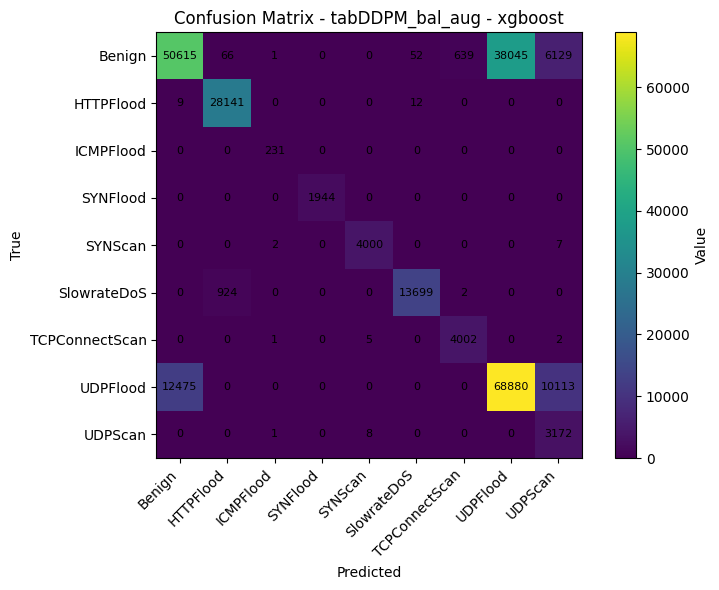

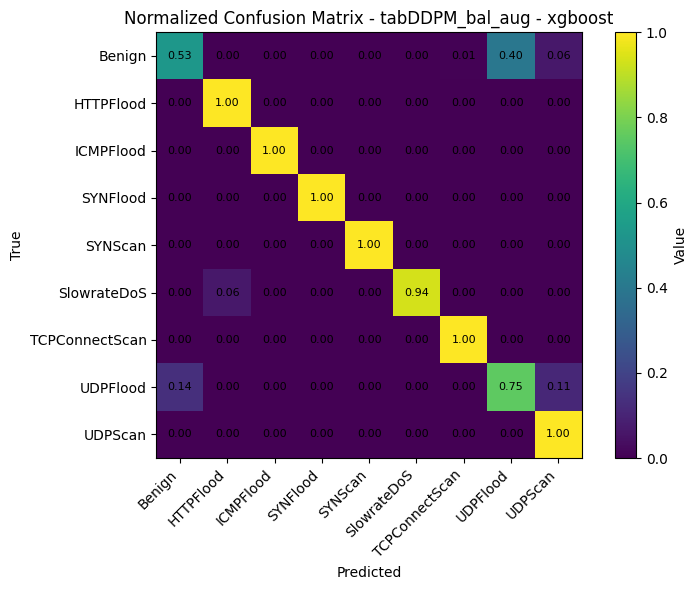

OK  xgboost   5G-NIDD_Aug_tabDDPM/Balanced/test_input_with_label.csv  acc=0.7183  bal_acc=0.9124  f1_macro=0.8302
------------------------------------------------------------------------------------------------------------------------
Loading lightgbm from classifier_training_gbdt/5gnidd_tabddpm_bal_aug_train/lightgbm_model.txt


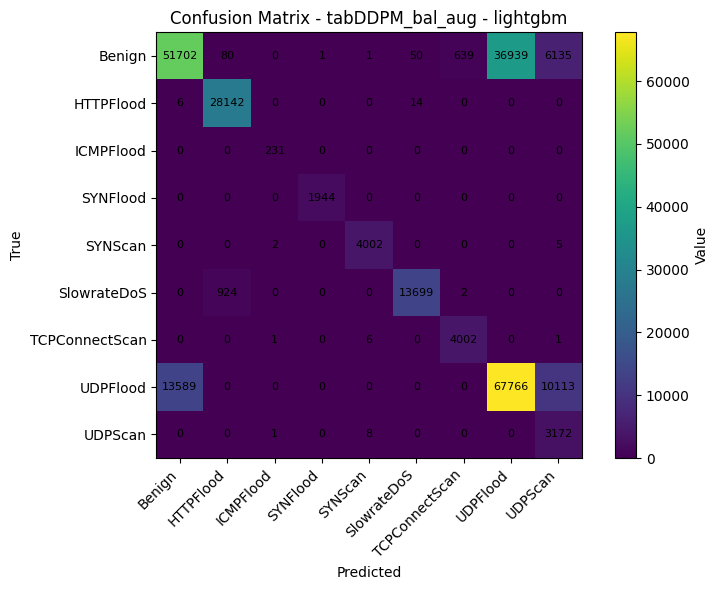

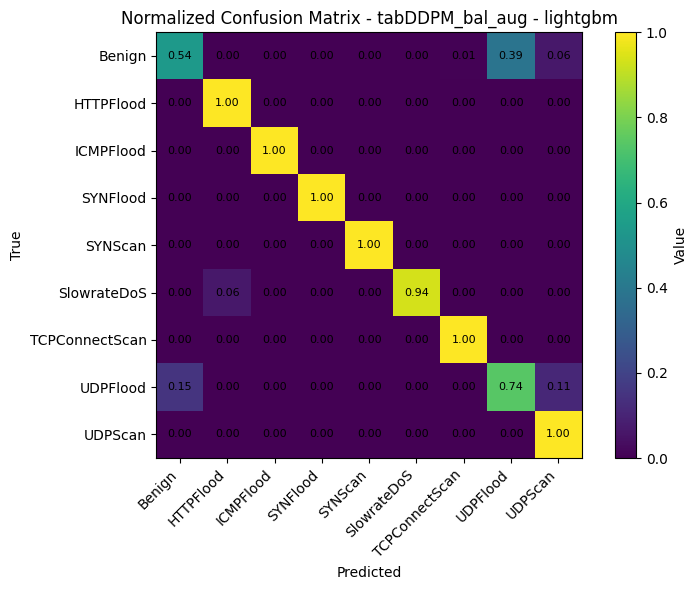

OK  lightgbm  5G-NIDD_Aug_tabDDPM/Balanced/test_input_with_label.csv  acc=0.7182  bal_acc=0.9124  f1_macro=0.8306
------------------------------------------------------------------------------------------------------------------------
Loading catboost from classifier_training_gbdt/5gnidd_tabddpm_bal_aug_train/catboost_model.cbm


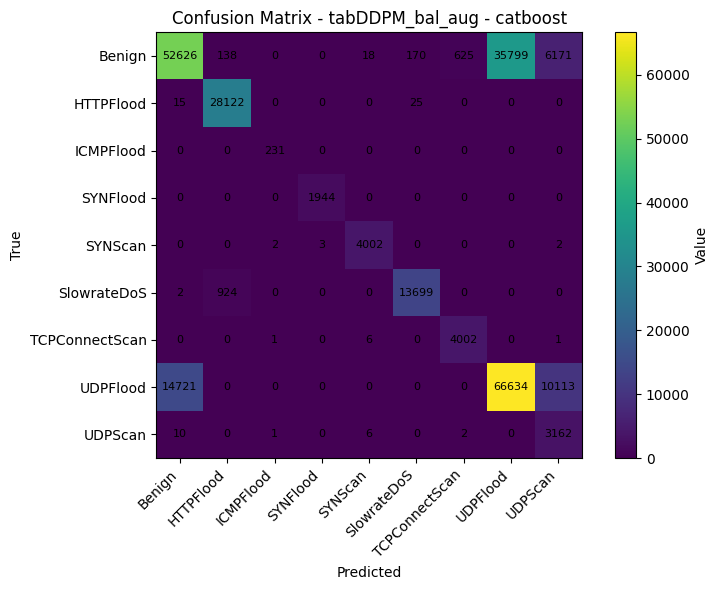

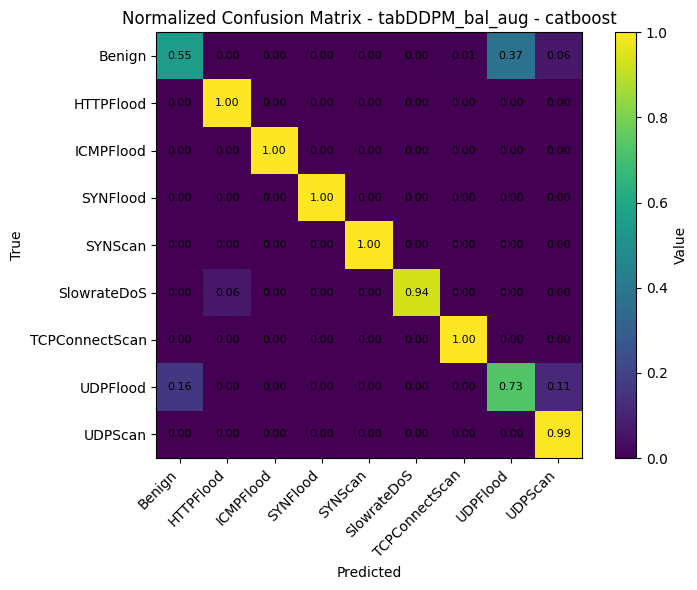

OK  catboost  5G-NIDD_Aug_tabDDPM/Balanced/test_input_with_label.csv  acc=0.7173  bal_acc=0.9116  f1_macro=0.8296
RUN: tabDDPM_perclass_bal_aug
DATASET_KEY: 5gnidd_tabddpm_perclass_bal_aug_train
FILES: 1
------------------------------------------------------------------------------------------------------------------------
Loading xgboost from classifier_training_gbdt/5gnidd_tabddpm_perclass_bal_aug_train/xgboost_model.json


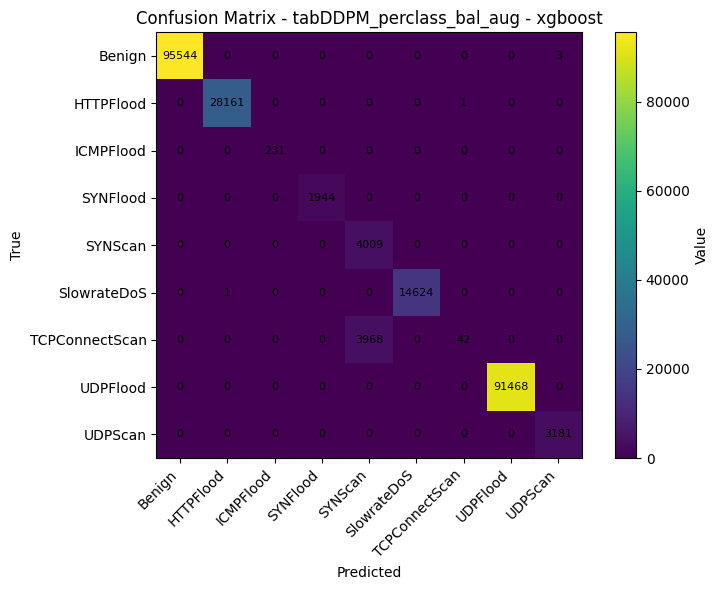

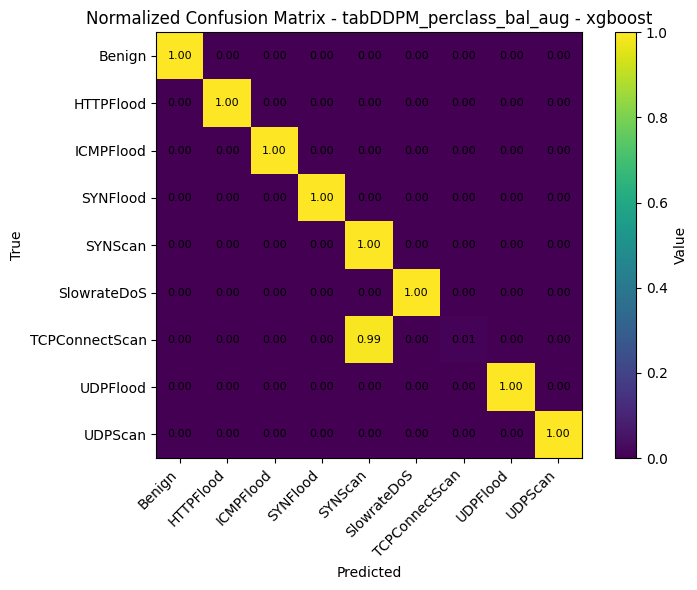

OK  xgboost   Datasets/augmented_per_class_datasets/tabddpm/test_input_with_label_merged.csv  acc=0.9837  bal_acc=0.8900  f1_macro=0.8543
------------------------------------------------------------------------------------------------------------------------
Loading lightgbm from classifier_training_gbdt/5gnidd_tabddpm_perclass_bal_aug_train/lightgbm_model.txt


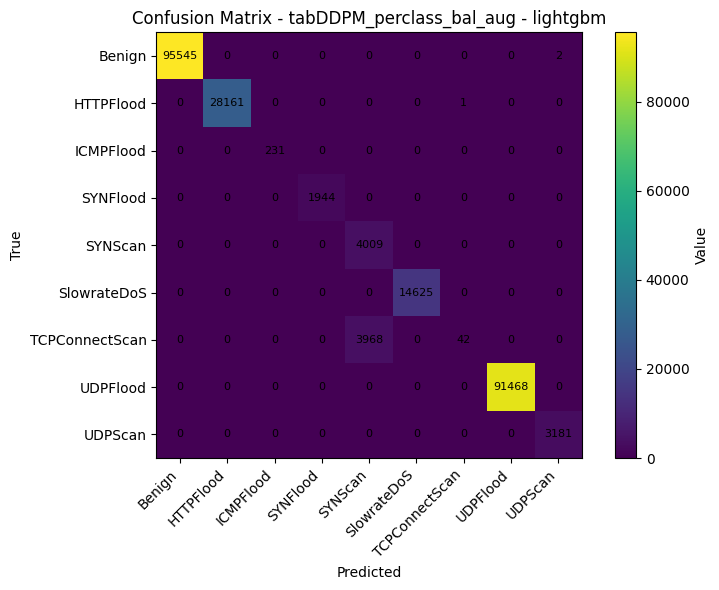

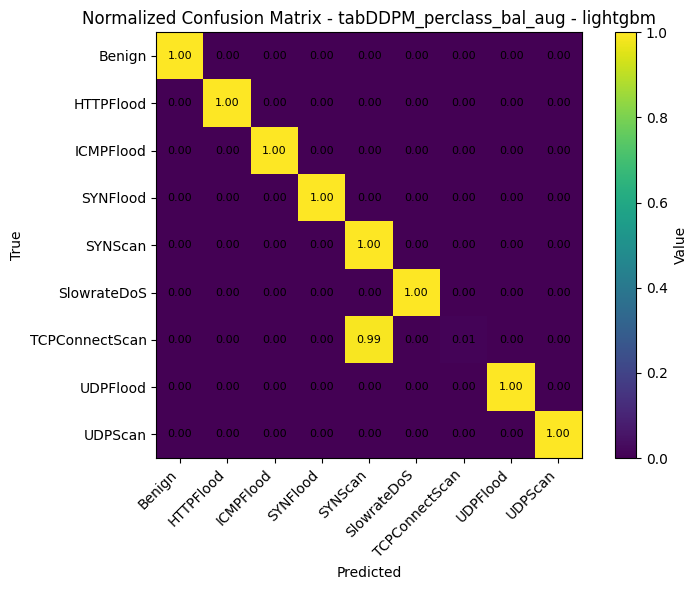

OK  lightgbm  Datasets/augmented_per_class_datasets/tabddpm/test_input_with_label_merged.csv  acc=0.9837  bal_acc=0.8900  f1_macro=0.8544
------------------------------------------------------------------------------------------------------------------------
Loading catboost from classifier_training_gbdt/5gnidd_tabddpm_perclass_bal_aug_train/catboost_model.cbm


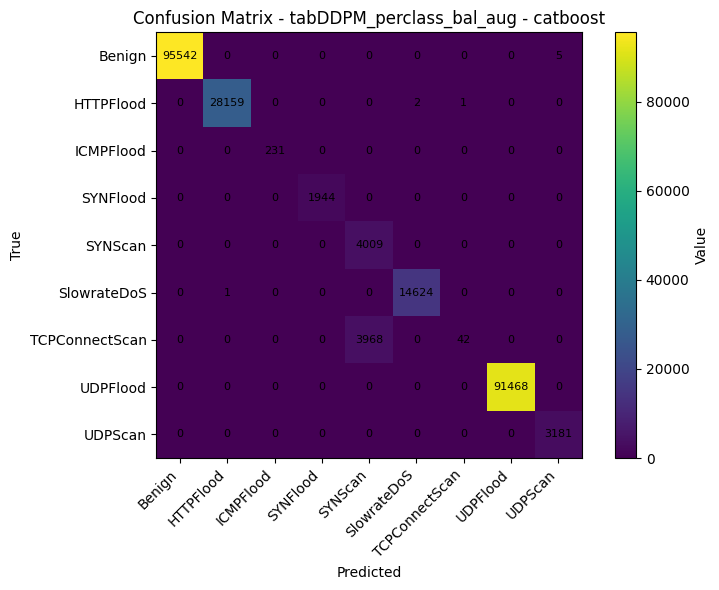

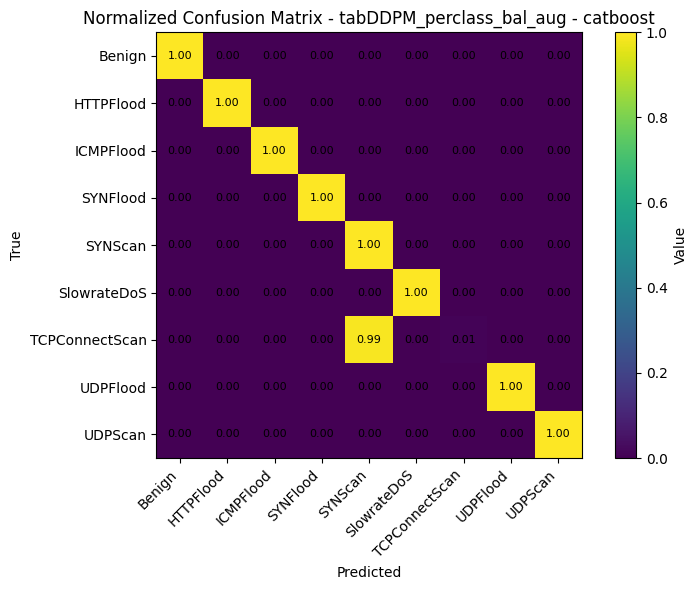

OK  catboost  Datasets/augmented_per_class_datasets/tabddpm/test_input_with_label_merged.csv  acc=0.9836  bal_acc=0.8900  f1_macro=0.8543
RUN: not_aug_raw
DATASET_KEY: 5gnidd_not_aug_raw_train
FILES: 1
------------------------------------------------------------------------------------------------------------------------
Loading xgboost from classifier_training_gbdt/5gnidd_not_aug_raw_train/xgboost_model.json


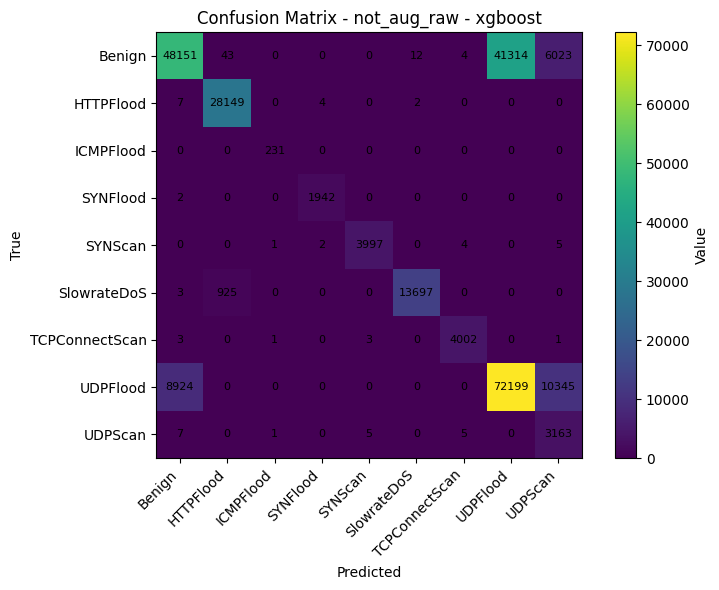

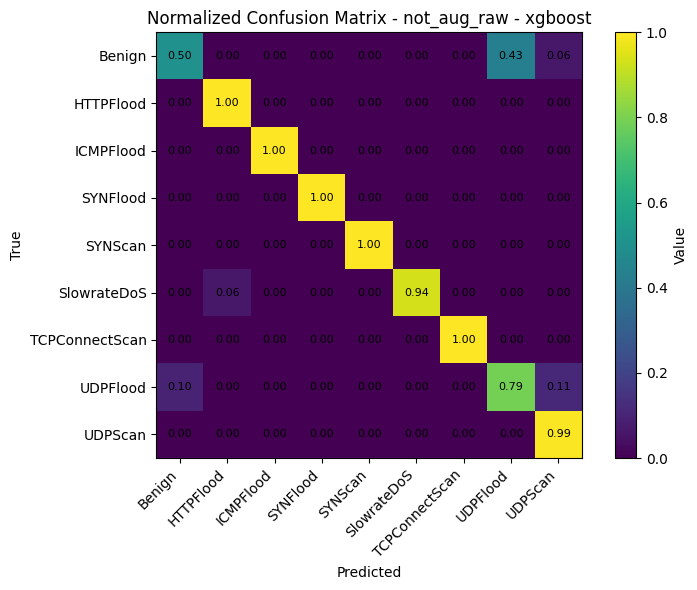

OK  xgboost   Datasets/prepped_raw/test_input_with_label.csv  acc=0.7218  bal_acc=0.9131  f1_macro=0.8389
------------------------------------------------------------------------------------------------------------------------
Loading lightgbm from classifier_training_gbdt/5gnidd_not_aug_raw_train/lightgbm_model.txt


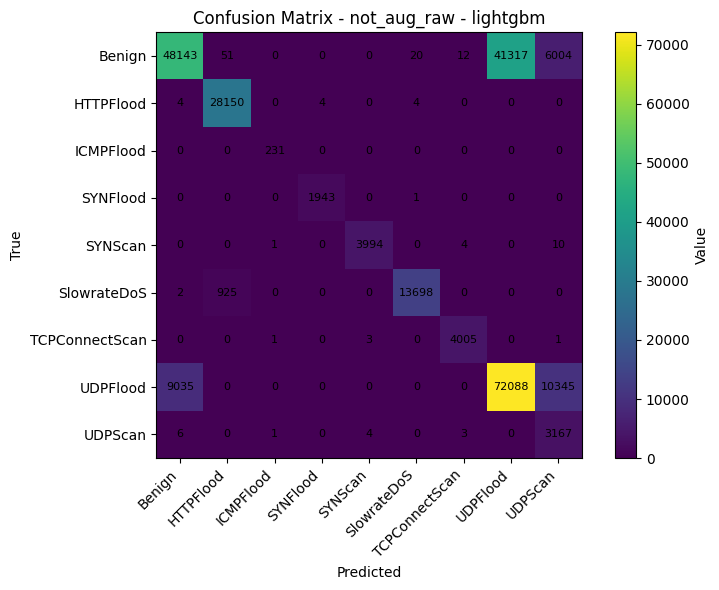

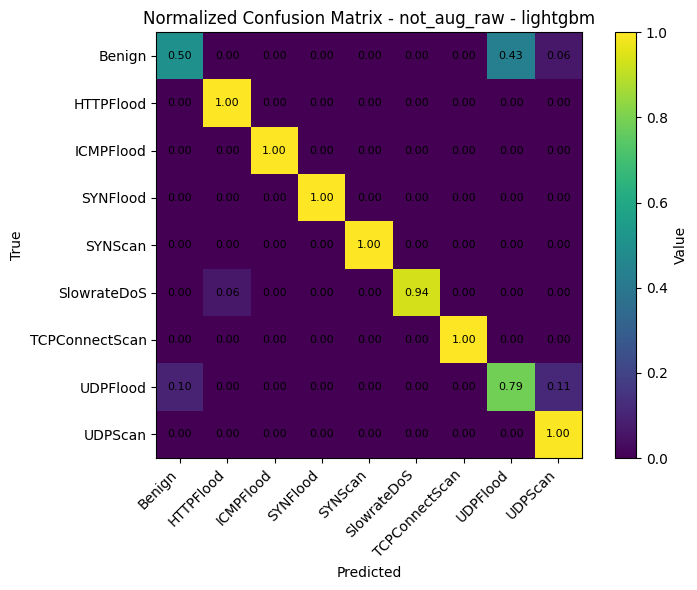

OK  lightgbm  Datasets/prepped_raw/test_input_with_label.csv  acc=0.7214  bal_acc=0.9131  f1_macro=0.8388
------------------------------------------------------------------------------------------------------------------------
Loading catboost from classifier_training_gbdt/5gnidd_not_aug_raw_train/catboost_model.cbm


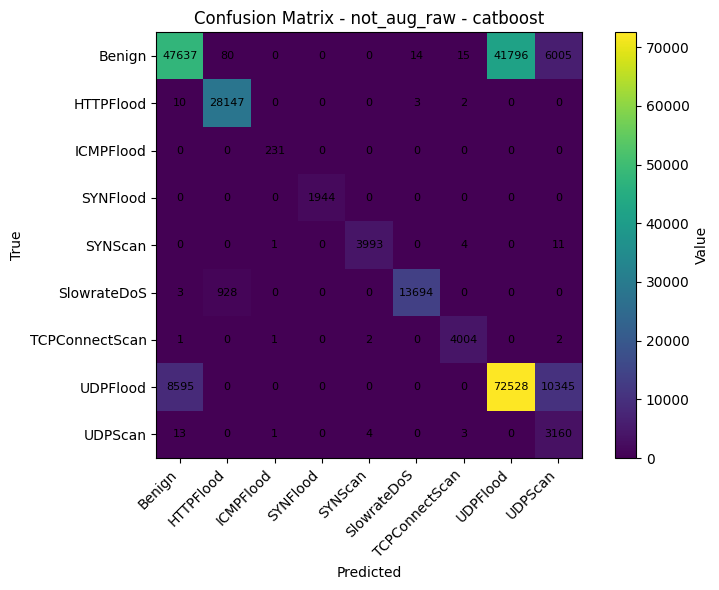

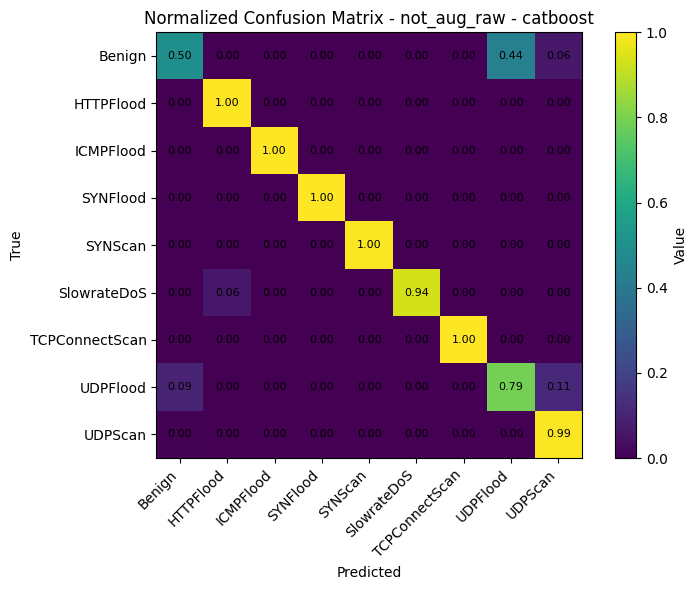

OK  catboost  Datasets/prepped_raw/test_input_with_label.csv  acc=0.7210  bal_acc=0.9128  f1_macro=0.8385
RUN: not_aug_dirty_raw
DATASET_KEY: 5gnidd_not_aug_dirty_raw_train
FILES: 1
------------------------------------------------------------------------------------------------------------------------
Loading xgboost from classifier_training_gbdt/5gnidd_not_aug_dirty_raw_train/xgboost_model.json


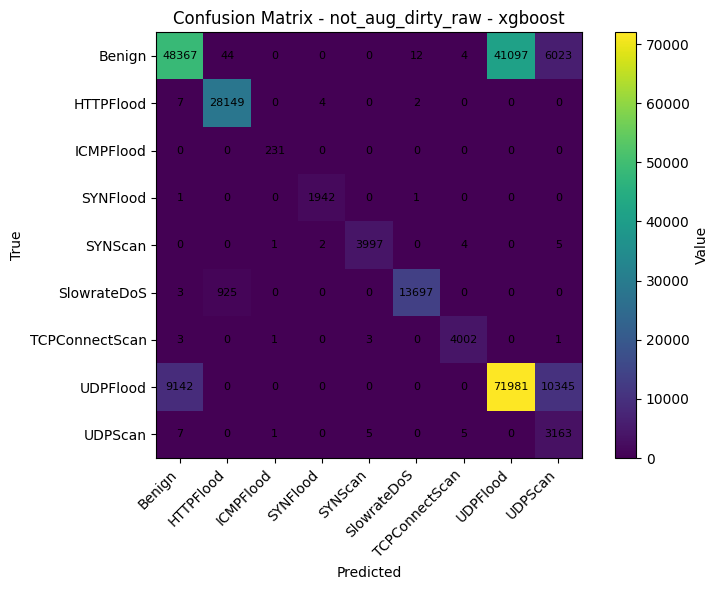

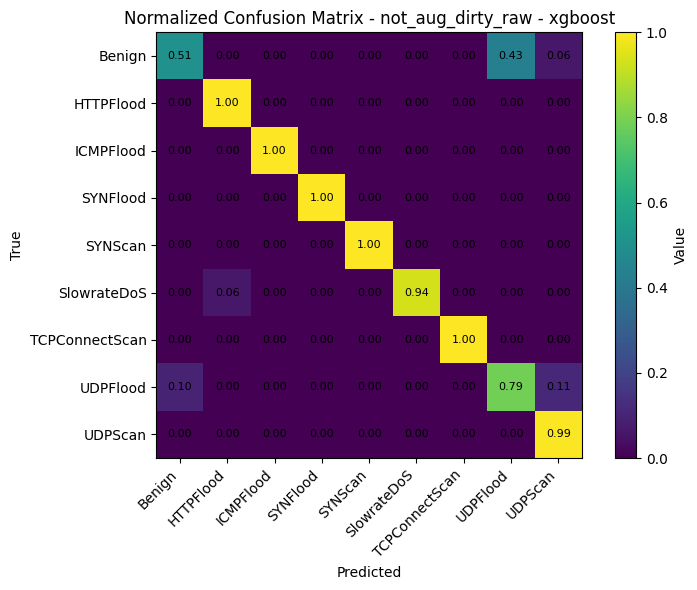

OK  xgboost   Datasets/Encoded_test_raw_243177.csv  acc=0.7218  bal_acc=0.9131  f1_macro=0.8389
------------------------------------------------------------------------------------------------------------------------
Loading lightgbm from classifier_training_gbdt/5gnidd_not_aug_dirty_raw_train/lightgbm_model.txt


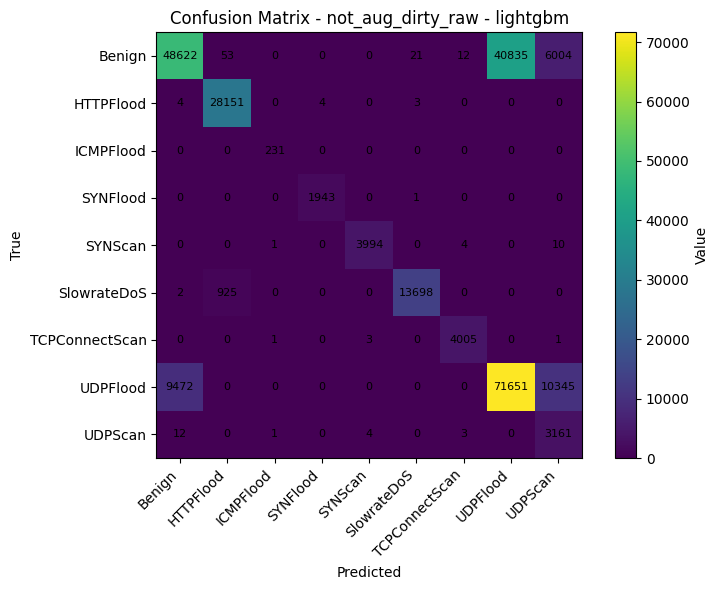

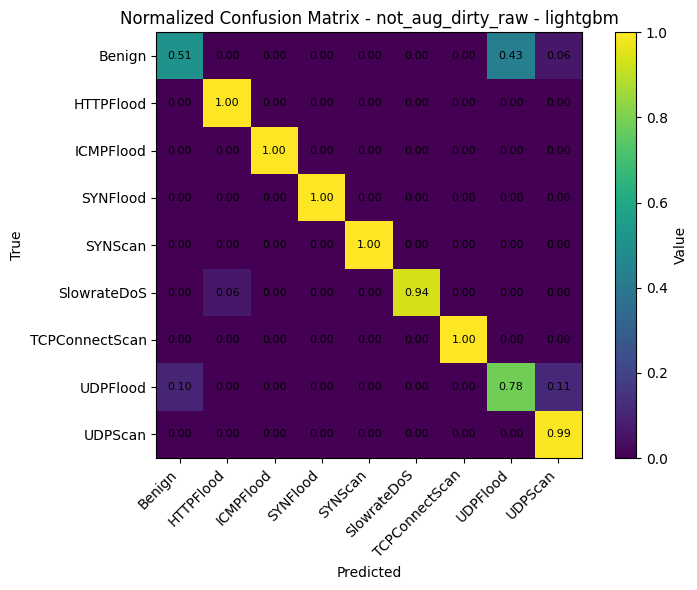

OK  lightgbm  Datasets/Encoded_test_raw_243177.csv  acc=0.7215  bal_acc=0.9130  f1_macro=0.8388
------------------------------------------------------------------------------------------------------------------------
Loading catboost from classifier_training_gbdt/5gnidd_not_aug_dirty_raw_train/catboost_model.cbm


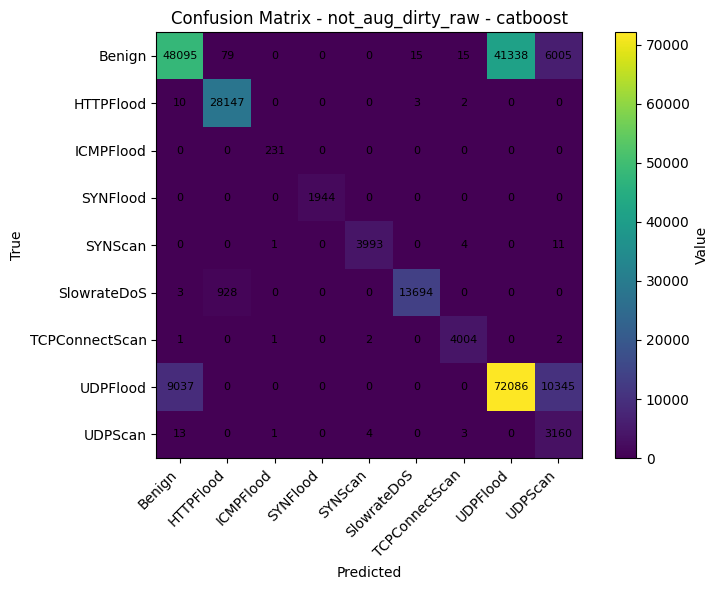

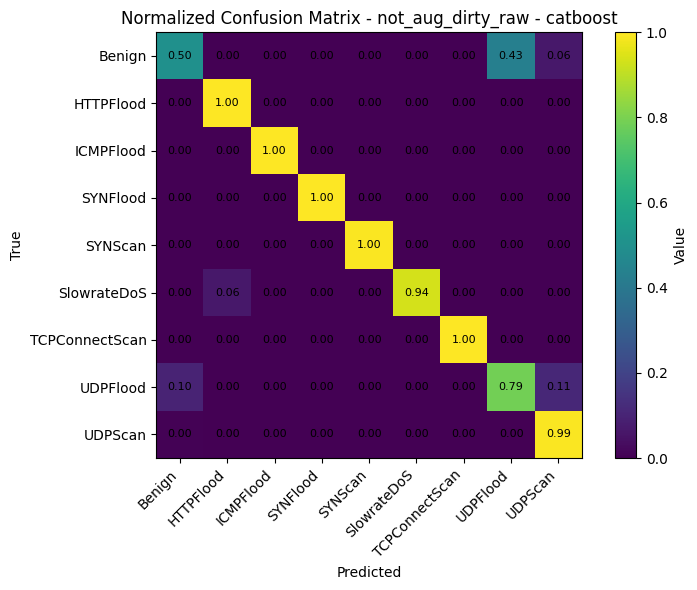

OK  catboost  Datasets/Encoded_test_raw_243177.csv  acc=0.7211  bal_acc=0.9128  f1_macro=0.8386
RUN: not_aug_bal_raw
DATASET_KEY: 5gnidd_not_aug_bal_raw_train
FILES: 1
------------------------------------------------------------------------------------------------------------------------
Loading xgboost from classifier_training_gbdt/5gnidd_not_aug_bal_raw_train/xgboost_model.json


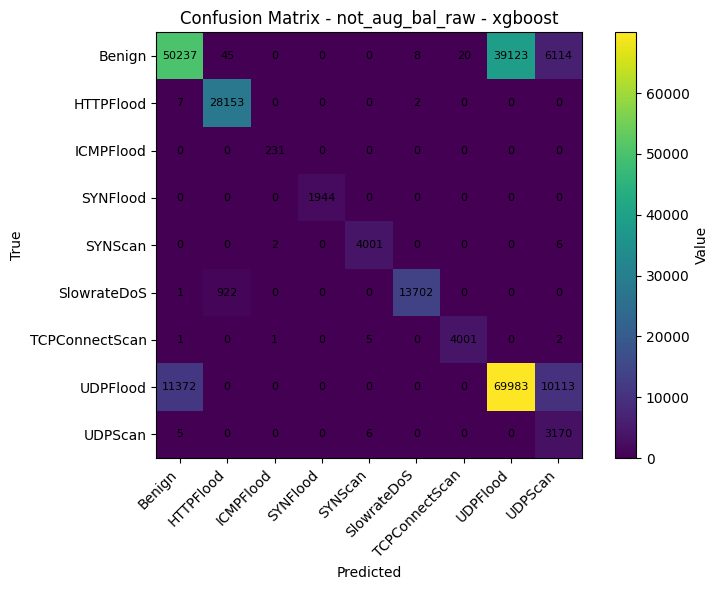

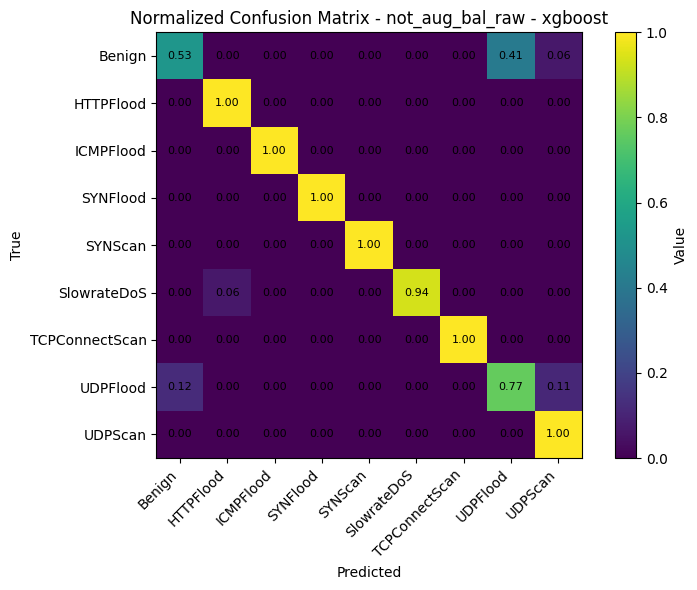

OK  xgboost   5G-NIDD_Aug_tabDDPM/Balanced/test_input_with_label.csv  acc=0.7214  bal_acc=0.9133  f1_macro=0.8395
------------------------------------------------------------------------------------------------------------------------
Loading lightgbm from classifier_training_gbdt/5gnidd_not_aug_bal_raw_train/lightgbm_model.txt


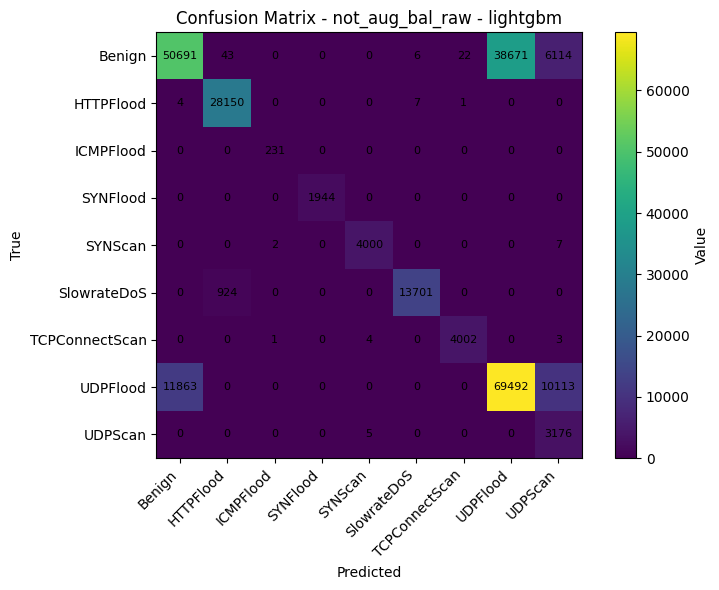

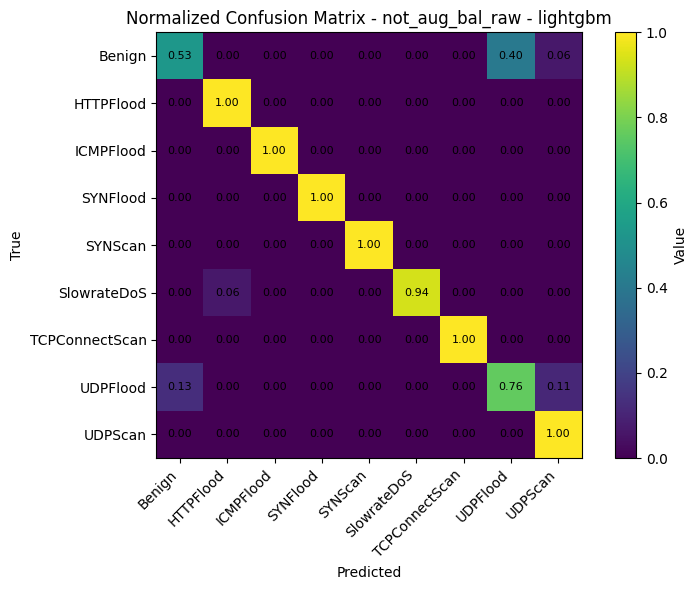

OK  lightgbm  5G-NIDD_Aug_tabDDPM/Balanced/test_input_with_label.csv  acc=0.7212  bal_acc=0.9134  f1_macro=0.8395
------------------------------------------------------------------------------------------------------------------------
Loading catboost from classifier_training_gbdt/5gnidd_not_aug_bal_raw_train/catboost_model.cbm


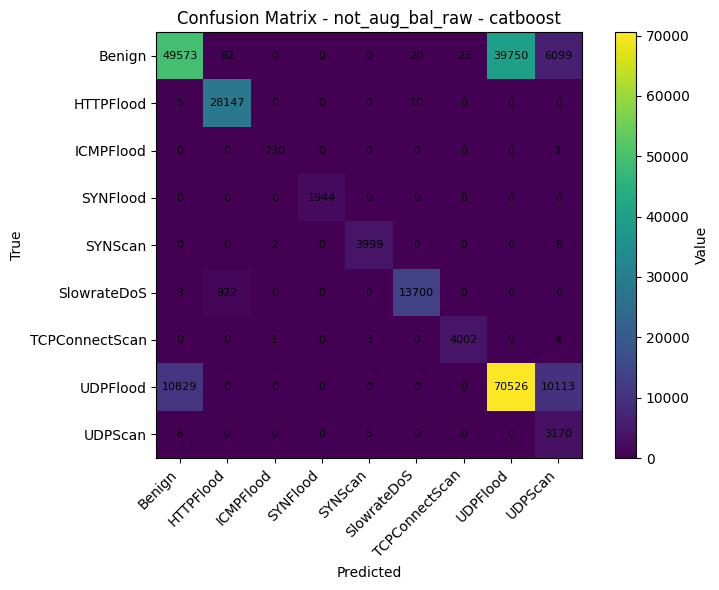

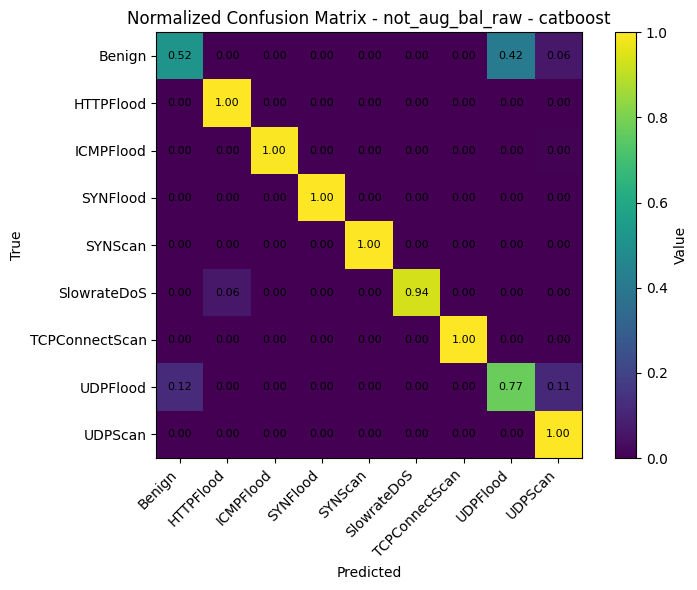

OK  catboost  5G-NIDD_Aug_tabDDPM/Balanced/test_input_with_label.csv  acc=0.7208  bal_acc=0.9126  f1_macro=0.8388
RUN: CTGAN_bal_aug
DATASET_KEY: 5gnidd_ctgan_bal_aug_train
FILES: 1
------------------------------------------------------------------------------------------------------------------------
Loading xgboost from classifier_training_gbdt/5gnidd_ctgan_bal_aug_train/xgboost_model.json


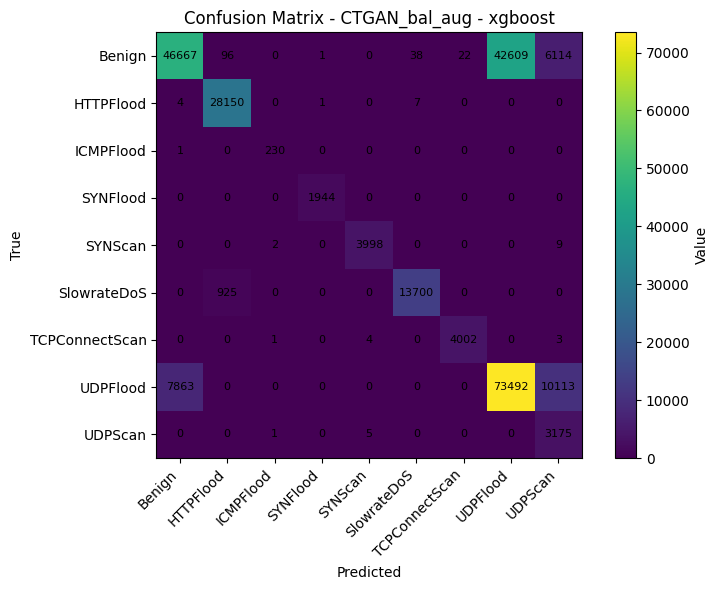

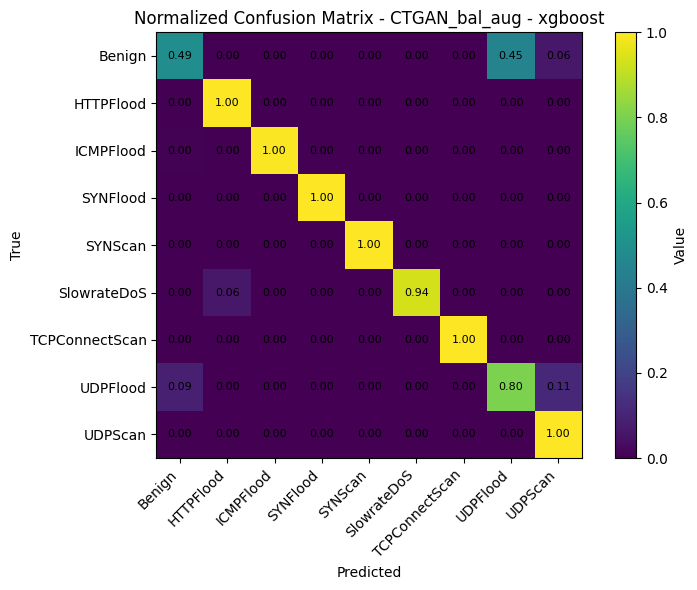

OK  xgboost   5G-NIDD_Aug_CTGAN/Balanced/test_input_with_label.csv  acc=0.7211  bal_acc=0.9130  f1_macro=0.8379
------------------------------------------------------------------------------------------------------------------------
Loading lightgbm from classifier_training_gbdt/5gnidd_ctgan_bal_aug_train/lightgbm_model.txt


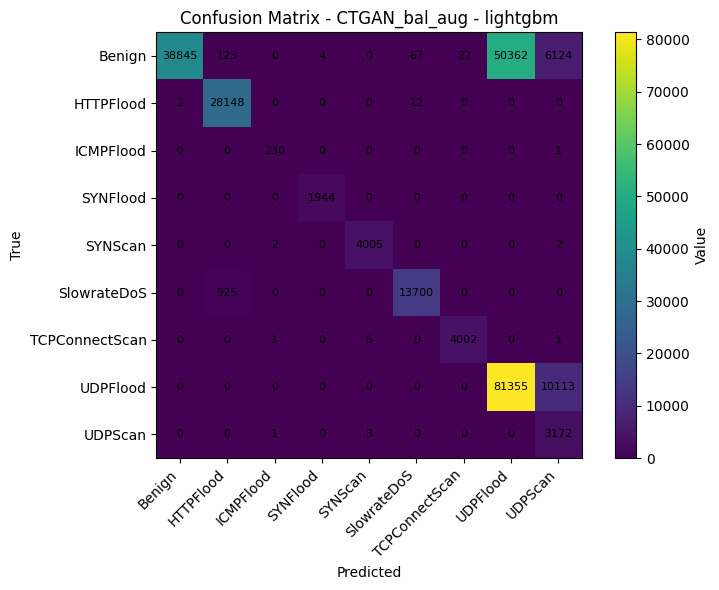

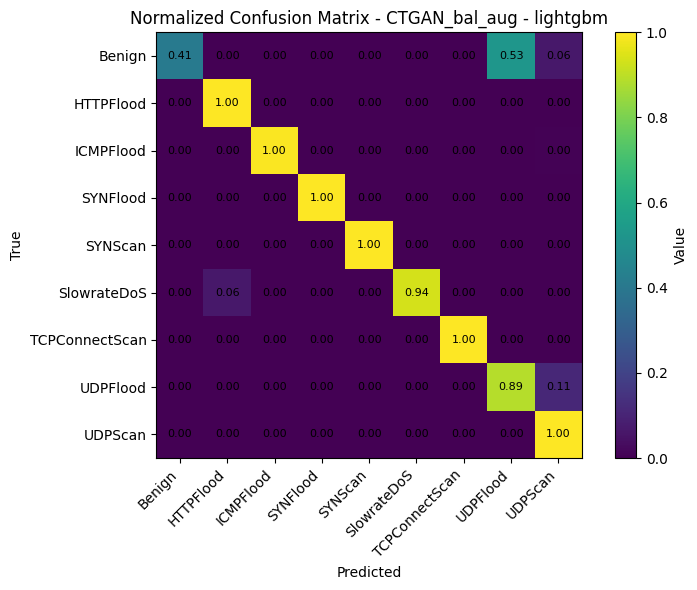

OK  lightgbm  5G-NIDD_Aug_CTGAN/Balanced/test_input_with_label.csv  acc=0.7213  bal_acc=0.9136  f1_macro=0.8351
------------------------------------------------------------------------------------------------------------------------
Loading catboost from classifier_training_gbdt/5gnidd_ctgan_bal_aug_train/catboost_model.cbm


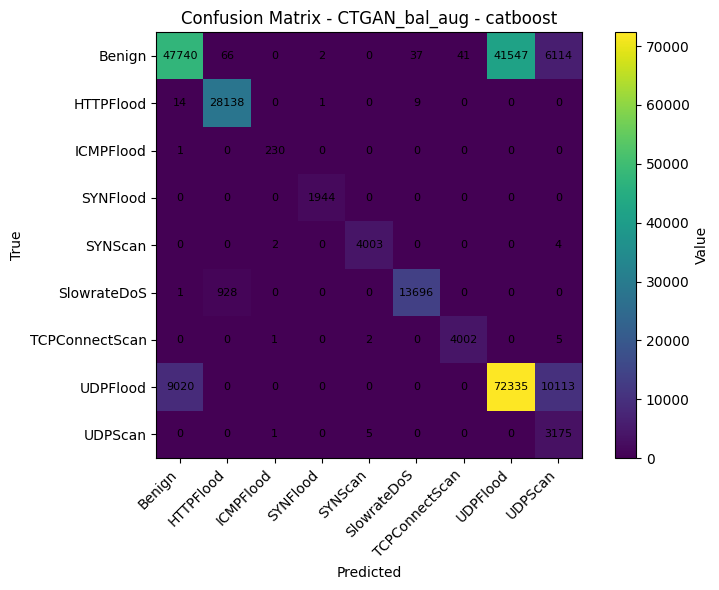

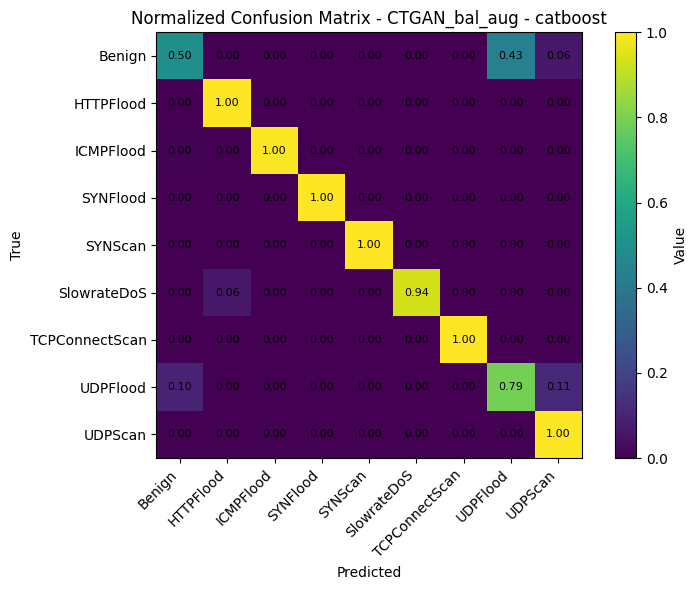

OK  catboost  5G-NIDD_Aug_CTGAN/Balanced/test_input_with_label.csv  acc=0.7207  bal_acc=0.9129  f1_macro=0.8379
RUN: CTGAN_perclass_bal_aug
DATASET_KEY: 5gnidd_ctgan_perclass_bal_aug_train
FILES: 1
------------------------------------------------------------------------------------------------------------------------
Loading xgboost from classifier_training_gbdt/5gnidd_ctgan_perclass_bal_aug_train/xgboost_model.json


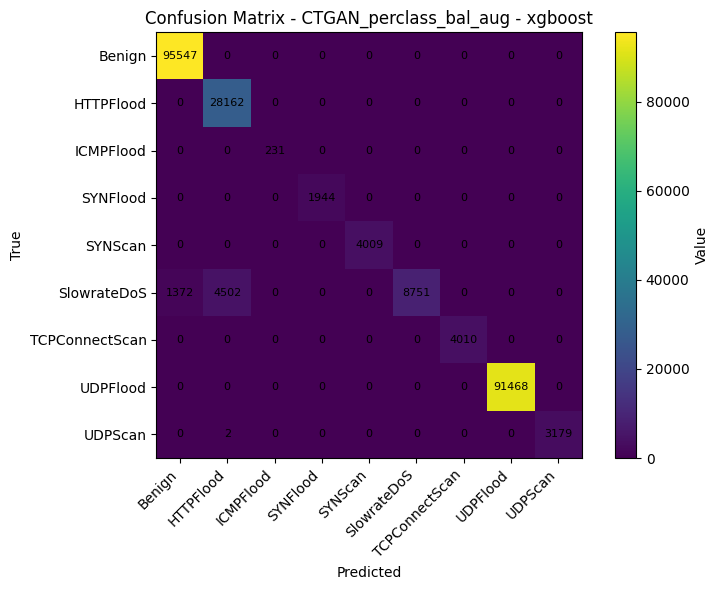

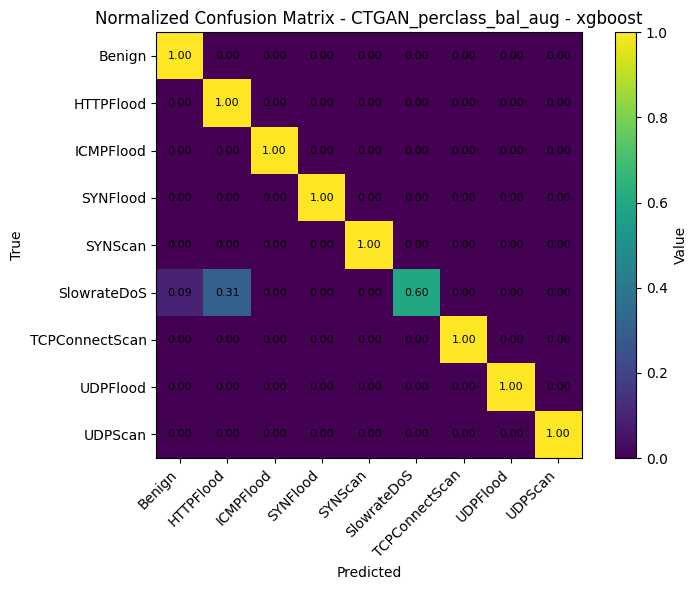

OK  xgboost   Datasets/augmented_per_class_datasets/ctgan/test_input_with_label_merged.csv  acc=0.9758  bal_acc=0.9553  f1_macro=0.9630
------------------------------------------------------------------------------------------------------------------------
Loading lightgbm from classifier_training_gbdt/5gnidd_ctgan_perclass_bal_aug_train/lightgbm_model.txt


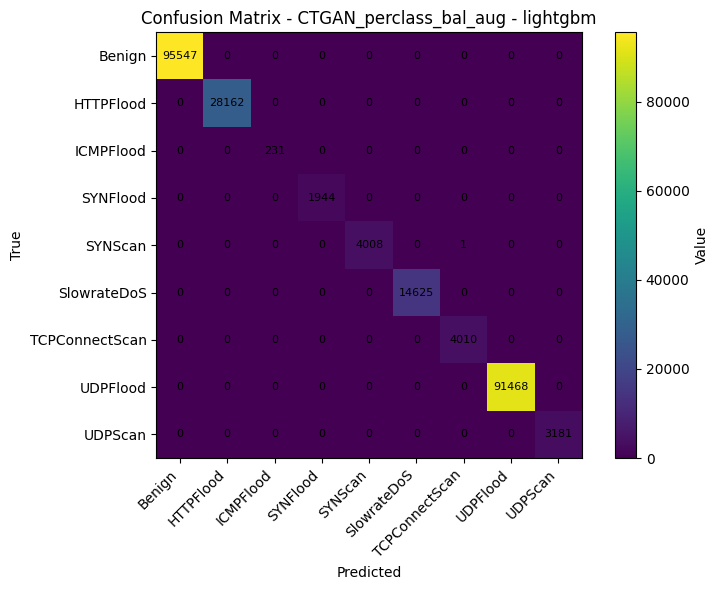

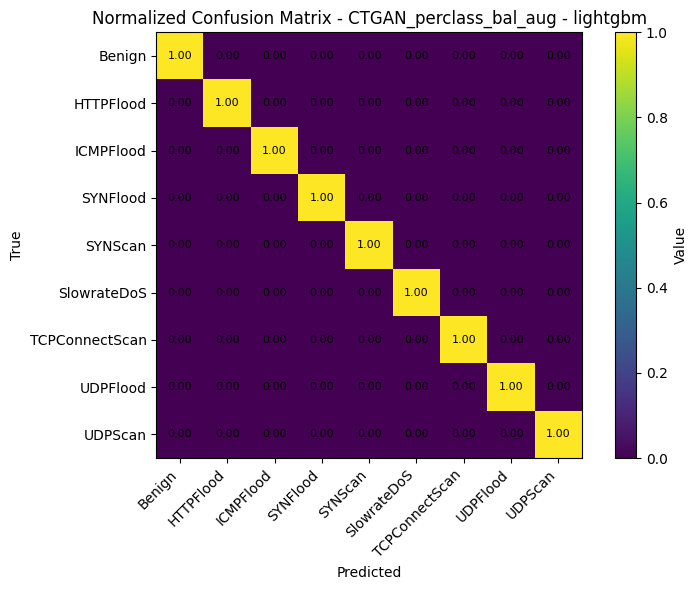

OK  lightgbm  Datasets/augmented_per_class_datasets/ctgan/test_input_with_label_merged.csv  acc=1.0000  bal_acc=1.0000  f1_macro=1.0000
------------------------------------------------------------------------------------------------------------------------
Loading catboost from classifier_training_gbdt/5gnidd_ctgan_perclass_bal_aug_train/catboost_model.cbm


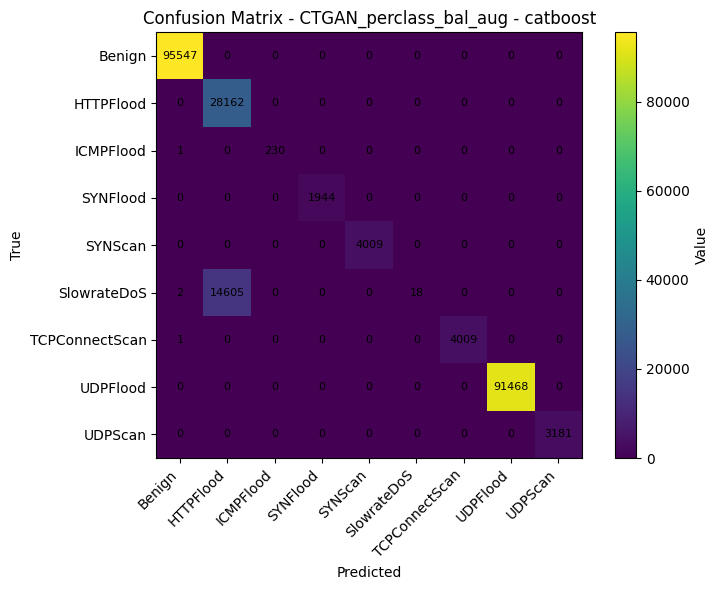

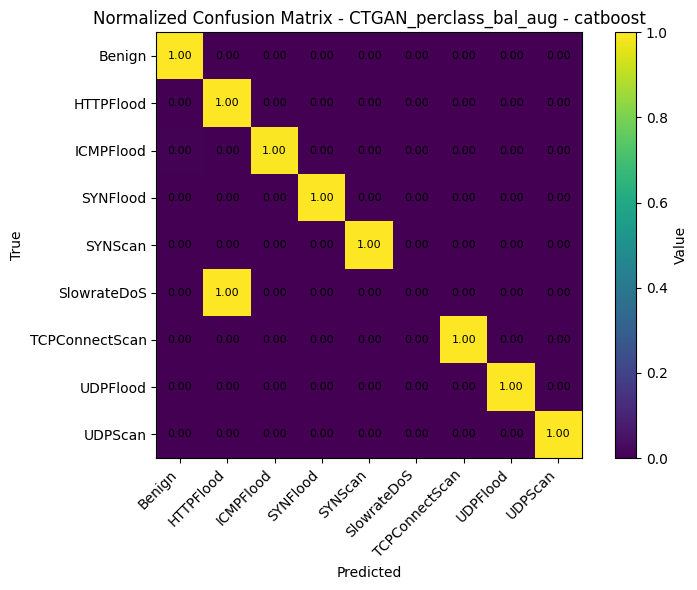

OK  catboost  Datasets/augmented_per_class_datasets/ctgan/test_input_with_label_merged.csv  acc=0.9399  bal_acc=0.8885  f1_macro=0.8660
Evaluation finished.
Results: 21
Errors: 0
Saved:
 - outputs_mapped_batch_comparison/mapped_batch_summary.json
 - outputs_mapped_batch_comparison/mapped_batch_errors.json


In [20]:
def run_one_file(dataset_key: str, model_type: str, model, file_path: str, feature_cols: Optional[List[str]]) -> dict:
    cfg = DATASET_CONFIGS[dataset_key]
    label_col = cfg["label_col"]
    label_mapping = cfg["label_mapping"]
    inv_label_mapping = {v: k for k, v in label_mapping.items()}

    df = pd.read_csv(file_path)
    X, y = ensure_feature_alignment(df, feature_cols=feature_cols, label_col=label_col)
    X = align_features_for_model(X, model_type=model_type, model=model, feature_cols_fallback=feature_cols, strict=True)

    if "n_features" in cfg and X.shape[1] != cfg["n_features"]:
        print(f"[warn] {dataset_key}/{model_type}: expected {cfg['n_features']} features, got {X.shape[1]}")

    proba = predict_proba(model_type, model, X)
    if proba.ndim != 2 or proba.shape[1] != len(inv_label_mapping):
        raise ValueError(f"{dataset_key}/{model_type}: expected proba shape (n_rows,{len(inv_label_mapping)}), got {proba.shape}")

    y_pred_int = np.argmax(proba, axis=1)
    y_pred_label = [inv_label_mapping[int(i)] for i in y_pred_int]

    result = {
        "y_pred_int": y_pred_int,
        "y_pred_label": y_pred_label,
        "proba": proba,
        "y_true_raw": y,
        "inv_label_mapping": inv_label_mapping,
    }

    if y is not None:
        y_true_int = coerce_labels_to_int(y, label_mapping)
        if y_true_int.isna().any():
            bad = y[y_true_int.isna()].unique().tolist()
            raise ValueError(f"Labels not in mapping: {bad}")
        result["y_true_int"] = y_true_int.astype(int).to_numpy()

    return result

ensure_dir(OUTPUT_DIR)
all_results = []
all_errors = []
per_class_collection = []

for run in RUNS:
    run_name = run["name"]
    dataset_key = run["dataset_key"]
    cfg = DATASET_CONFIGS[dataset_key]
    feature_cols = FEATURE_COLS_MAP.get(dataset_key)
    files = expand_files(run)

    print("=" * 120)
    print(f"RUN: {run_name}")
    print(f"DATASET_KEY: {dataset_key}")
    print(f"FILES: {len(files)}")

    for model_type in MODELS_TO_RUN:
        if "models" not in cfg or model_type not in cfg["models"]:
            msg = f"[skip] Missing model type in JSON: {model_type}"
            print(msg)
            all_errors.append({"run": run_name, "dataset_key": dataset_key, "model_type": model_type, "error": msg})
            continue

        raw_model_path = cfg["models"][model_type].get("model_path")
        model_path = resolve_model_path(raw_model_path, BASE_DIR)
        if not model_path or not os.path.exists(model_path):
            msg = f"[skip] Missing model file: {model_path}"
            print(msg)
            all_errors.append({"run": run_name, "dataset_key": dataset_key, "model_type": model_type, "error": msg})
            continue

        print("-" * 120)
        print(f"Loading {model_type} from {model_path}")
        model = load_model(model_type, model_path)

        out_dir = make_output_subdir(OUTPUT_DIR, dataset_key, model_type, run_name)

        for fp in files:
            try:
                pred = run_one_file(dataset_key, model_type, model, fp, feature_cols=feature_cols)
                base = f"{Path(fp).parent.name}_{Path(fp).stem}"

                pred_df = pd.DataFrame({
                    "y_pred": pred["y_pred_int"],
                    "y_pred_label": pred["y_pred_label"],
                })
                for k in range(pred["proba"].shape[1]):
                    pred_df[f"proba_{k}_{pred['inv_label_mapping'][k]}"] = pred["proba"][:, k]

                predictions_csv = os.path.join(out_dir, f"predictions_{base}.csv")
                pred_df.to_csv(predictions_csv, index=False)

                record = {
                    "run": run_name,
                    "dataset_key": dataset_key,
                    "model_type": model_type,
                    "file": fp,
                    "predictions_csv": predictions_csv,
                    "n_rows": int(len(pred["y_pred_int"])),
                    "has_labels": bool("y_true_int" in pred),
                }

                if "y_true_int" in pred:
                    y_true_int = pred["y_true_int"]
                    y_pred_int = pred["y_pred_int"]
                    inv = pred["inv_label_mapping"]

                    global_metrics, per_class_df, cm, cm_norm, cls_report, target_names = compute_extended_metrics(y_true_int, y_pred_int, inv)

                    global_metrics_json = os.path.join(out_dir, f"global_metrics_{base}.json")
                    save_json(global_metrics, global_metrics_json)
                    global_metrics_csv = os.path.join(out_dir, f"global_metrics_{base}.csv")
                    pd.DataFrame([global_metrics]).to_csv(global_metrics_csv, index=False)

                    per_class_df = per_class_df.copy()
                    per_class_df.insert(0, "run", run_name)
                    per_class_df.insert(1, "dataset_key", dataset_key)
                    per_class_df.insert(2, "model_type", model_type)
                    per_class_df.insert(3, "file", fp)
                    per_class_csv = os.path.join(out_dir, f"per_class_metrics_{base}.csv")
                    per_class_df.to_csv(per_class_csv, index=False)

                    cm_df = pd.DataFrame(cm, index=target_names, columns=target_names)
                    cm_norm_df = pd.DataFrame(cm_norm, index=target_names, columns=target_names)
                    cm_csv = os.path.join(out_dir, f"confusion_matrix_{base}.csv")
                    cm_norm_csv = os.path.join(out_dir, f"confusion_matrix_normalized_{base}.csv")
                    cm_df.to_csv(cm_csv)
                    cm_norm_df.to_csv(cm_norm_csv)

                    if SAVE_PLOTS:
                        cm_png = os.path.join(out_dir, f"confusion_matrix_{base}.png")
                        cm_norm_png = os.path.join(out_dir, f"confusion_matrix_normalized_{base}.png")
                        save_confusion_matrix_plot(cm_df, f"Confusion Matrix - {run_name} - {model_type}", cm_png)
                        save_confusion_matrix_plot(cm_norm_df, f"Normalized Confusion Matrix - {run_name} - {model_type}", cm_norm_png)

                    record.update({
                        "global_metrics_json": global_metrics_json,
                        "global_metrics_csv": global_metrics_csv,
                        "per_class_metrics_csv": per_class_csv,
                        "confusion_matrix_csv": cm_csv,
                        "confusion_matrix_normalized_csv": cm_norm_csv,
                        "metrics": global_metrics,
                    })

                    for _, row in per_class_df.iterrows():
                        per_class_collection.append(row.to_dict())

                    print(
                        f"OK  {model_type:<8}  {Path(fp).as_posix()}  "
                        f"acc={global_metrics['accuracy']:.4f}  "
                        f"bal_acc={global_metrics['balanced_accuracy']:.4f}  "
                        f"f1_macro={global_metrics['f1_macro']:.4f}"
                    )
                else:
                    print(f"OK  {model_type:<8}  {Path(fp).as_posix()}  (no labels, predictions only)")

                all_results.append(record)

            except Exception as e:
                err = {"run": run_name, "dataset_key": dataset_key, "model_type": model_type, "file": fp, "error": str(e)}
                all_errors.append(err)
                print("[error]", err)

summary_json = os.path.join(OUTPUT_DIR, "mapped_batch_summary.json")
errors_json = os.path.join(OUTPUT_DIR, "mapped_batch_errors.json")
save_json(all_results, summary_json)
save_json(all_errors, errors_json)

print("=" * 120)
print("Evaluation finished.")
print("Results:", len(all_results))
print("Errors:", len(all_errors))
print("Saved:")
print(" -", summary_json)
print(" -", errors_json)

## 5) Build detailed comparison tables


In [21]:
flat_rows = []
for rec in all_results:
    row = {
        "run": rec["run"],
        "dataset_key": rec["dataset_key"],
        "model_type": rec["model_type"],
        "file": rec["file"],
        "predictions_csv": rec["predictions_csv"],
        "n_rows": rec["n_rows"],
        "has_labels": rec["has_labels"],
    }
    if "metrics" in rec:
        row.update(rec["metrics"])
    flat_rows.append(row)

comparison_dir = ensure_dir(os.path.join(OUTPUT_DIR, "comparison"))
plots_dir = ensure_dir(os.path.join(OUTPUT_DIR, "plots"))

global_comparison_df = pd.DataFrame(flat_rows)
global_comparison_csv = os.path.join(comparison_dir, "global_model_comparison.csv")
global_comparison_df.to_csv(global_comparison_csv, index=False)

per_class_comparison_df = pd.DataFrame(per_class_collection)
per_class_comparison_csv = os.path.join(comparison_dir, "per_class_model_comparison.csv")
per_class_comparison_df.to_csv(per_class_comparison_csv, index=False)

print("Saved comparison tables:")
print(" -", global_comparison_csv)
print(" -", per_class_comparison_csv)

if len(global_comparison_df) > 0:
    display(global_comparison_df.sort_values(["f1_macro", "balanced_accuracy"], ascending=False, na_position="last"))

Saved comparison tables:
 - outputs_mapped_batch_comparison/comparison/global_model_comparison.csv
 - outputs_mapped_batch_comparison/comparison/per_class_model_comparison.csv


,run,dataset_key,model_type,file,predictions_csv,n_rows,has_labels,accuracy,balanced_accuracy,precision_macro,...,recall_weighted,f1_weighted,precision_micro,recall_micro,f1_micro,mcc,cohen_kappa,attack_only_recall_macro,attack_only_f1_macro,benign_false_positive_rate
19,CTGAN_perclass_bal_aug,5gnidd_ctgan_perclass_bal_aug_train,lightgbm,Datasets/augmented_per_class_datasets/ctgan/te...,outputs_mapped_batch_comparison/5gnidd_ctgan_p...,243177,True,0.999996,0.999972,0.999972,...,0.999996,0.999996,0.999996,0.999996,0.999996,0.999994,0.999994,0.999969,0.999969,0.000000
18,CTGAN_perclass_bal_aug,5gnidd_ctgan_perclass_bal_aug_train,xgboost,Datasets/augmented_per_class_datasets/ctgan/te...,outputs_mapped_batch_comparison/5gnidd_ctgan_p...,243177,True,0.975837,0.955303,0.983107,...,0.975837,0.973507,0.975837,0.975837,0.975837,0.965332,0.964644,0.949716,0.959295,0.009294
20,CTGAN_perclass_bal_aug,5gnidd_ctgan_perclass_bal_aug_train,catboost,Datasets/augmented_per_class_datasets/ctgan/te...,outputs_mapped_batch_comparison/5gnidd_ctgan_p...,243177,True,0.939924,0.888517,0.962051,...,0.939924,0.916148,0.939924,0.939924,0.939924,0.916931,0.912040,0.874582,0.849282,0.000027
4,tabDDPM_perclass_bal_aug,5gnidd_tabddpm_perclass_bal_aug_train,lightgbm,Datasets/augmented_per_class_datasets/tabddpm/...,outputs_mapped_batch_comparison/5gnidd_tabddpm...,243177,True,0.983670,0.890046,0.942076,...,0.983670,0.978384,0.983670,0.983670,0.983670,0.976586,0.976207,0.876305,0.836168,0.000000
3,tabDDPM_perclass_bal_aug,5gnidd_tabddpm_perclass_bal_aug_train,xgboost,Datasets/augmented_per_class_datasets/tabddpm/...,outputs_mapped_batch_comparison/5gnidd_tabddpm...,243177,True,0.983662,0.890038,0.942037,...,0.983662,0.978375,0.983662,0.983662,0.983662,0.976574,0.976196,0.876296,0.836141,0.000000
5,tabDDPM_perclass_bal_aug,5gnidd_tabddpm_perclass_bal_aug_train,catboost,Datasets/augmented_per_class_datasets/tabddpm/...,outputs_mapped_batch_comparison/5gnidd_tabddpm...,243177,True,0.983646,0.890027,0.941952,...,0.983646,0.978359,0.983646,0.983646,0.983646,0.976551,0.976172,0.876287,0.836089,0.000000
13,not_aug_bal_raw,5gnidd_not_aug_bal_raw_train,lightgbm,5G-NIDD_Aug_tabDDPM/Balanced/test_input_with_l...,outputs_mapped_batch_comparison/5gnidd_not_aug...,243177,True,0.721232,0.913429,0.840160,...,0.721232,0.731289,0.721232,0.721232,0.721232,0.620984,0.608861,0.961290,0.864329,0.080383
12,not_aug_bal_raw,5gnidd_not_aug_bal_raw_train,xgboost,5G-NIDD_Aug_tabDDPM/Balanced/test_input_with_l...,outputs_mapped_batch_comparison/5gnidd_not_aug...,243177,True,0.721376,0.913307,0.840616,...,0.721376,0.731139,0.721376,0.721376,0.721376,0.621919,0.609091,0.961748,0.864517,0.077125
9,not_aug_dirty_raw,5gnidd_not_aug_dirty_raw_train,xgboost,Datasets/Encoded_test_raw_243177.csv,outputs_mapped_batch_comparison/5gnidd_not_aug...,243177,True,0.721816,0.913064,0.842631,...,0.721816,0.730442,0.721816,0.721816,0.721816,0.626202,0.609962,0.963920,0.864779,0.062067
6,not_aug_raw,5gnidd_not_aug_raw_train,xgboost,Datasets/prepped_raw/test_input_with_label.csv,outputs_mapped_batch_comparison/5gnidd_not_aug...,243177,True,0.721824,0.913077,0.842873,...,0.721824,0.730276,0.721824,0.721824,0.721824,0.626622,0.609989,0.964218,0.864864,0.060597


## 6) Comparison plots


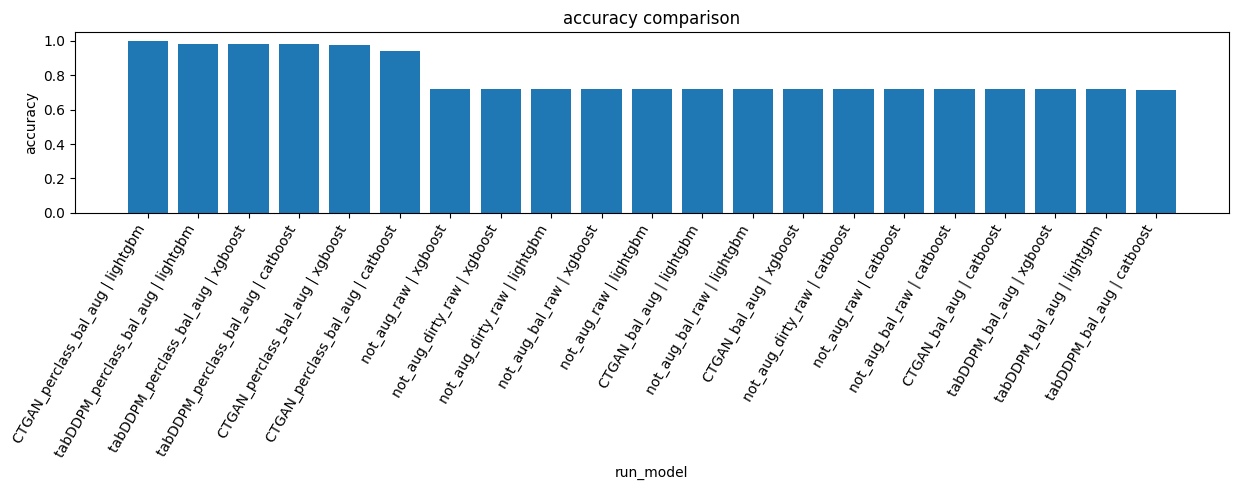

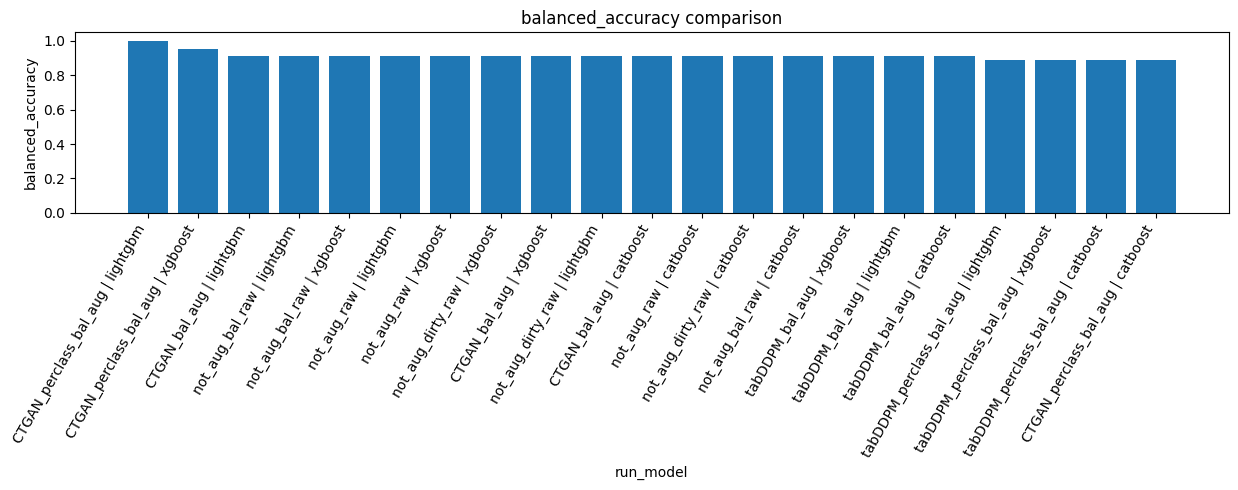

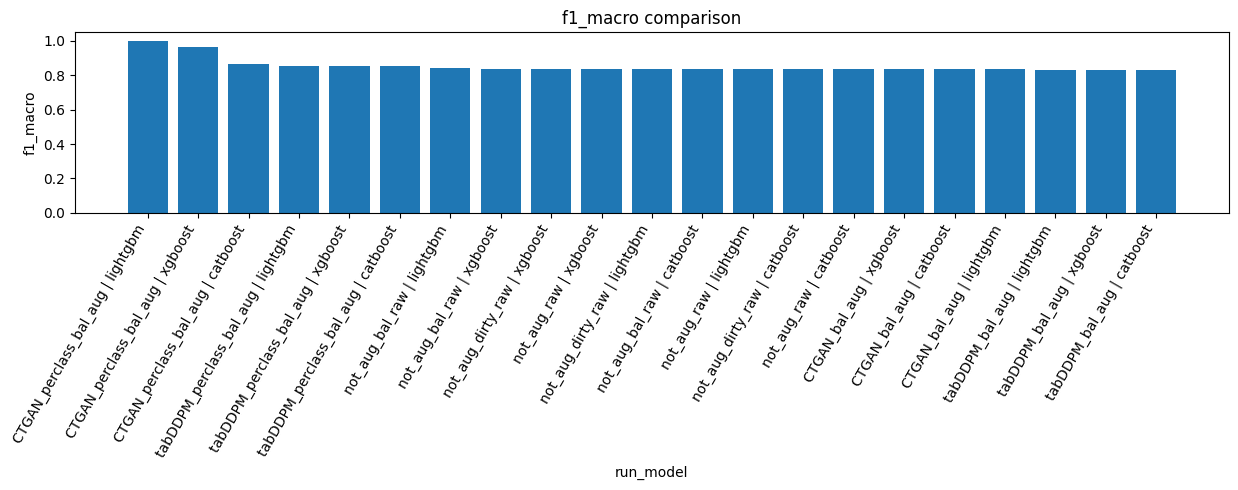

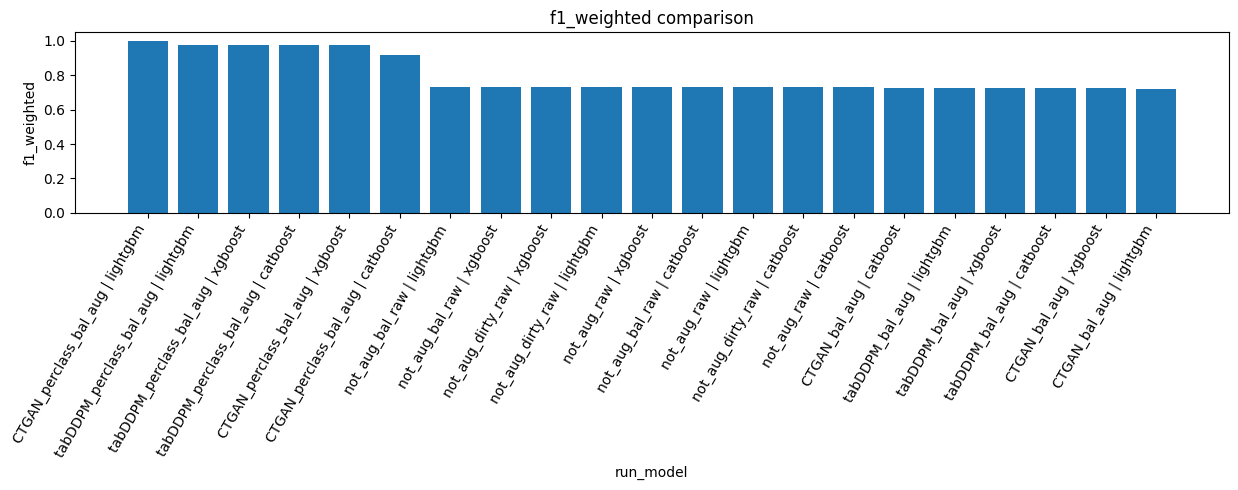

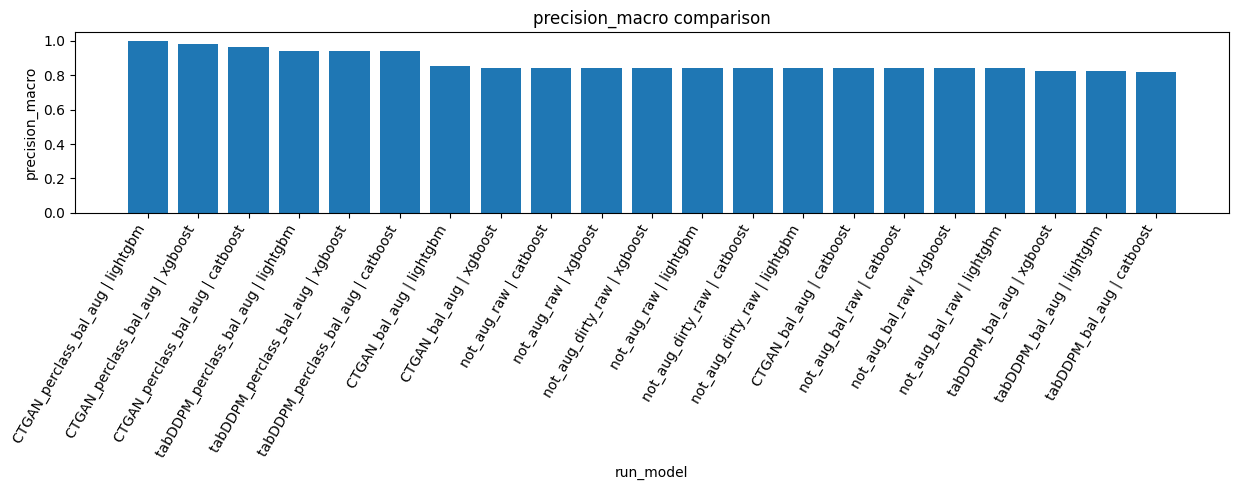

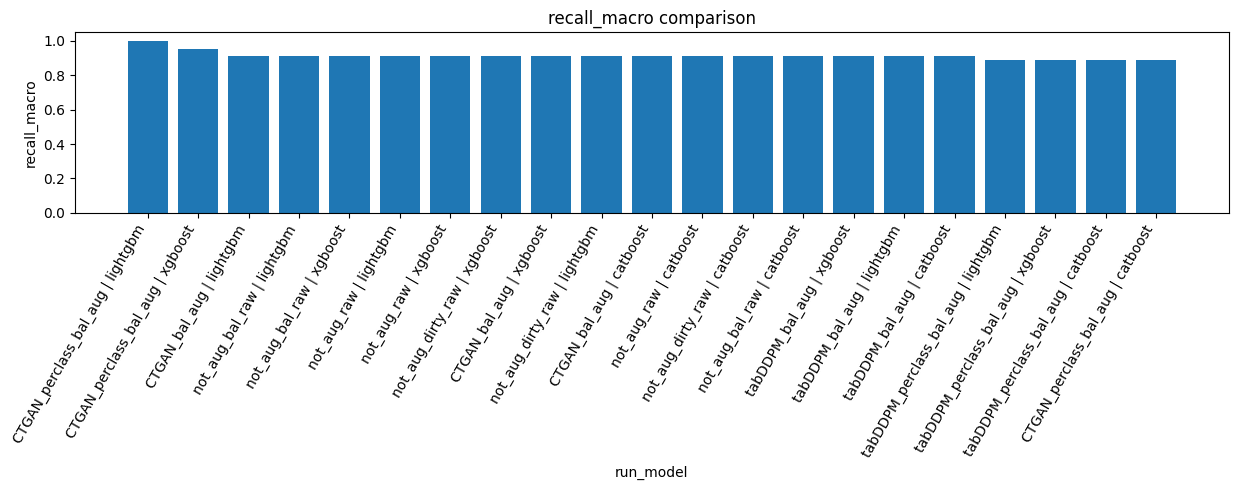

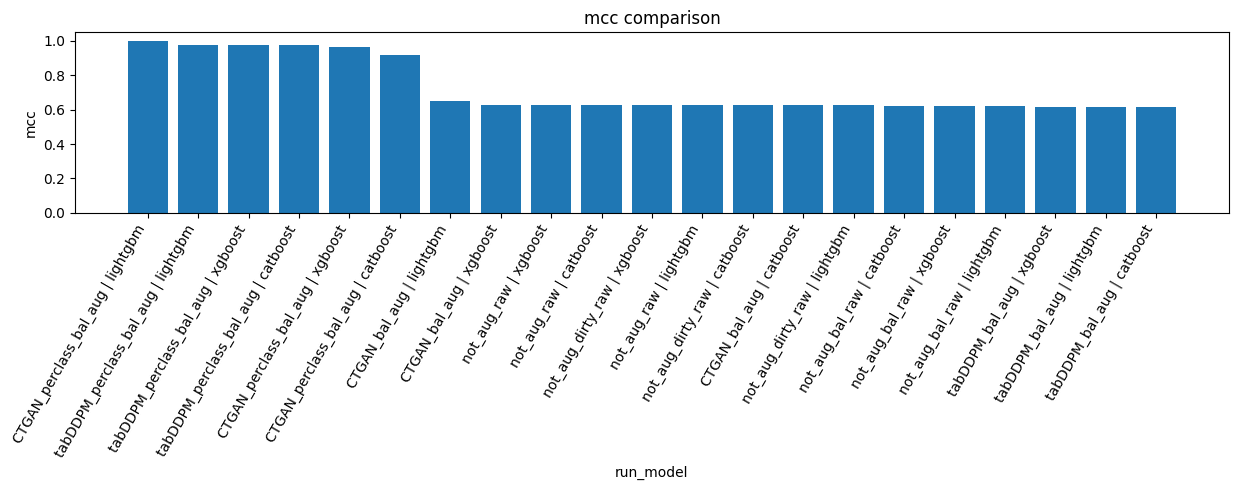

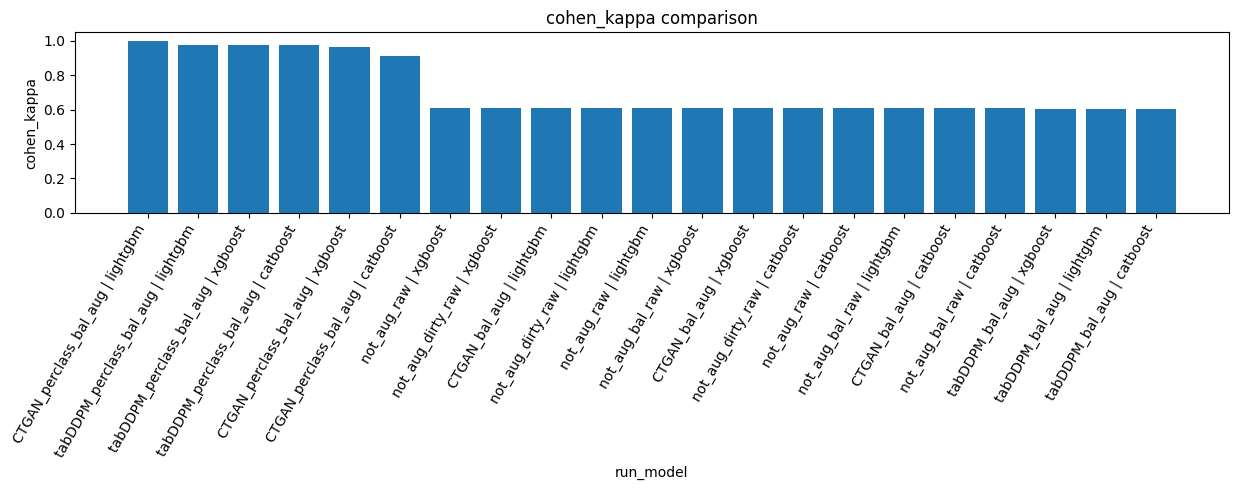

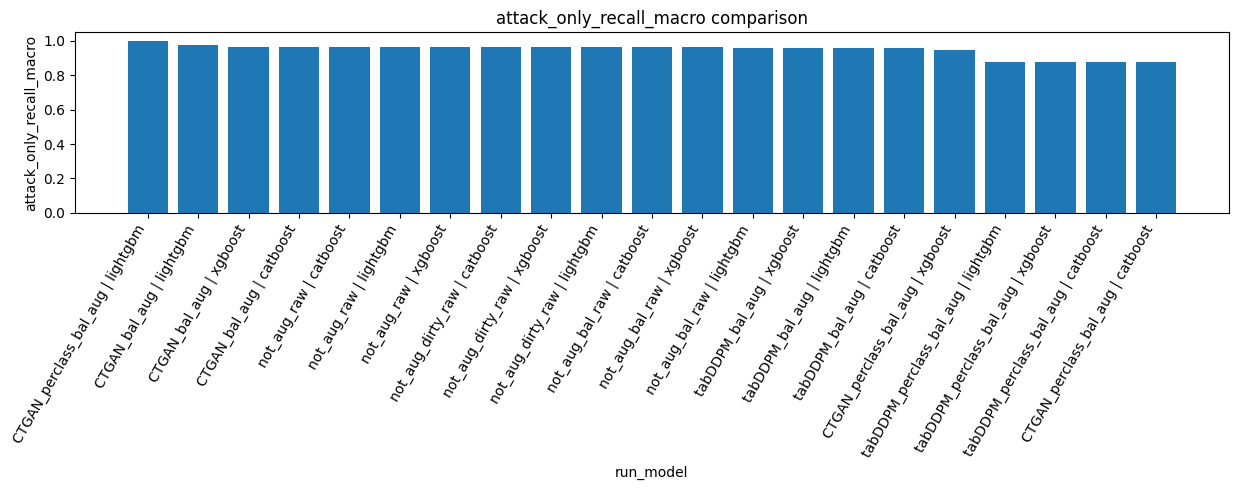

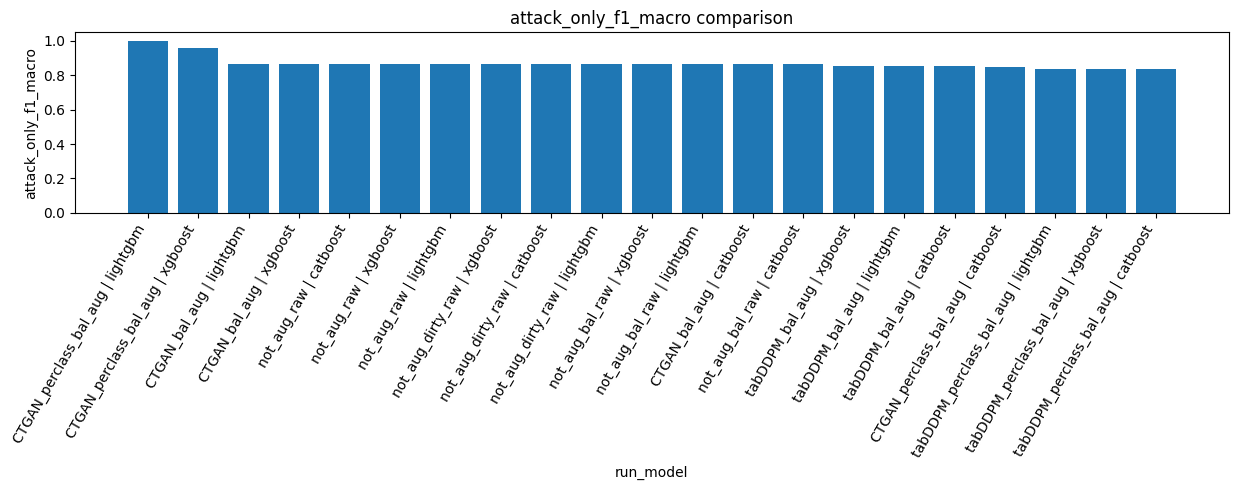

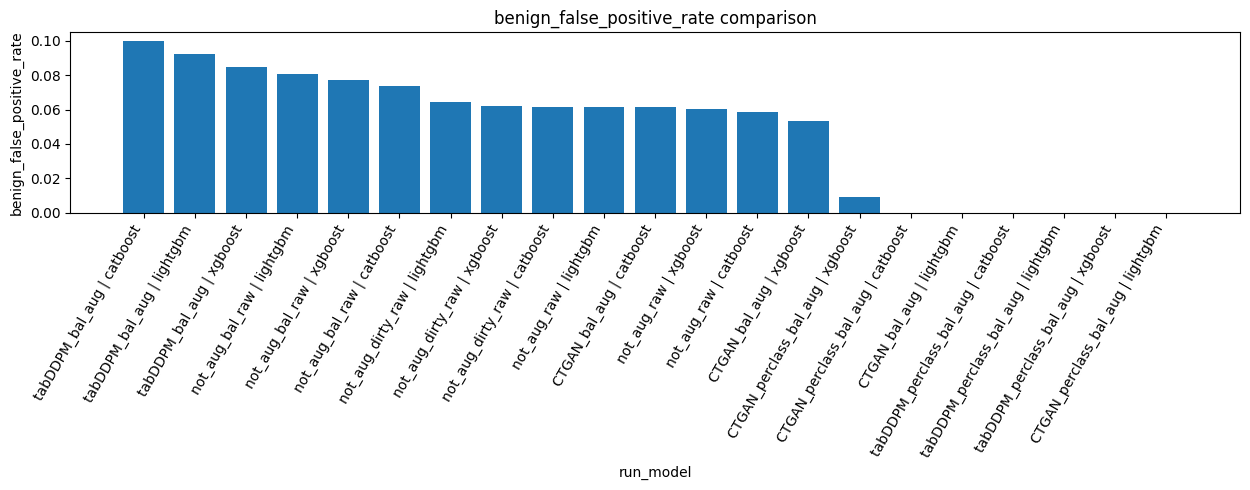

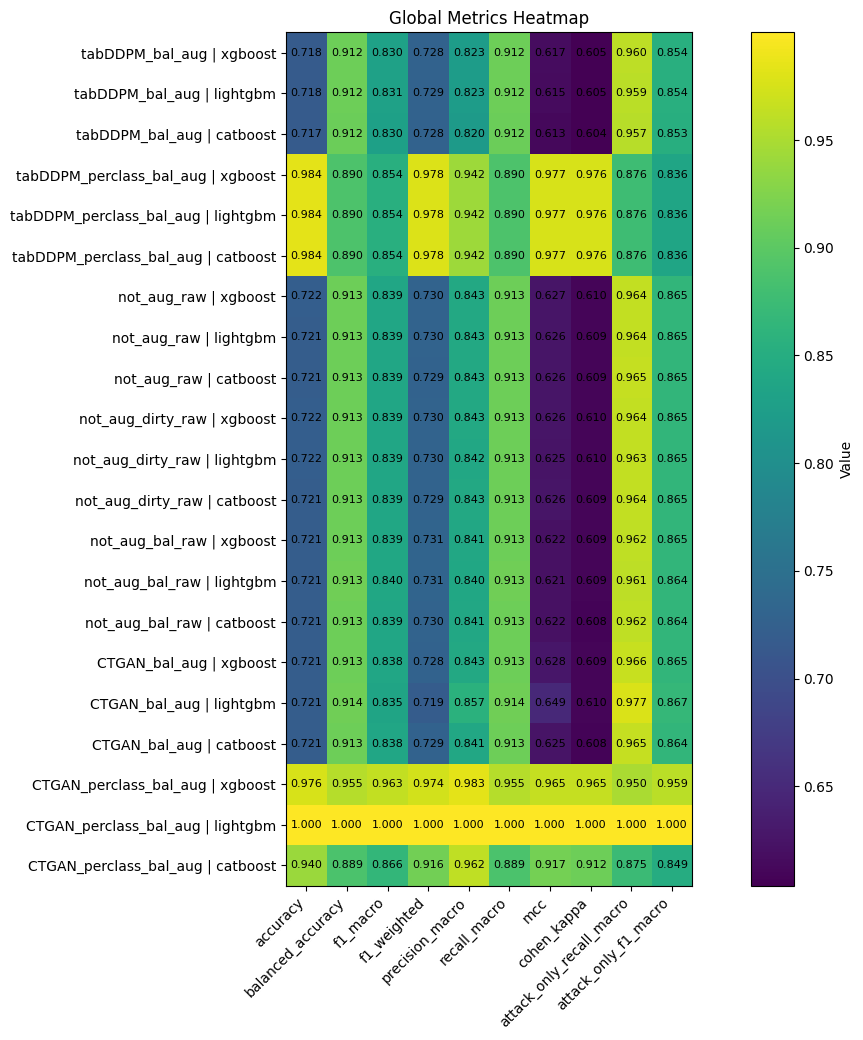

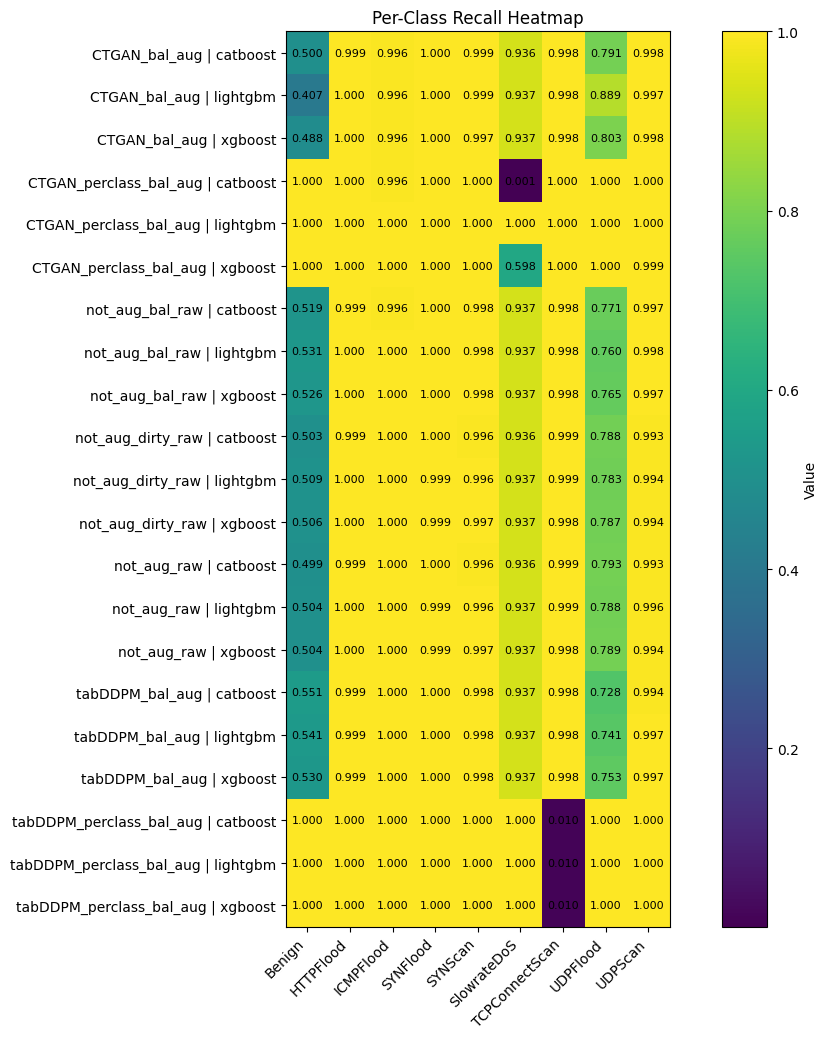

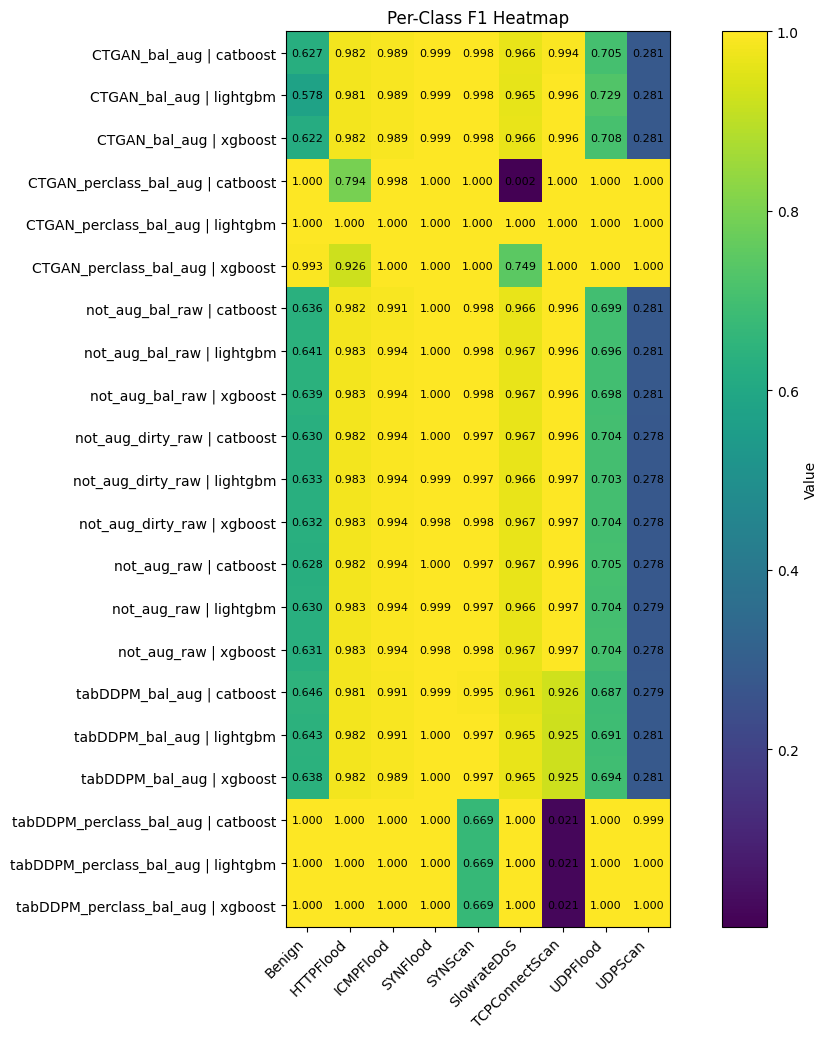

Plots saved under: outputs_mapped_batch_comparison/plots


In [22]:
if len(global_comparison_df) == 0:
    print("No comparison data available.")
else:
    plot_df = global_comparison_df[global_comparison_df["has_labels"] == True].copy()

    if len(plot_df) == 0:
        print("No labeled evaluation rows available for plotting.")
    else:
        plot_df["run_model"] = plot_df["run"] + " | " + plot_df["model_type"]

        metric_cols = [
            "accuracy",
            "balanced_accuracy",
            "f1_macro",
            "f1_weighted",
            "precision_macro",
            "recall_macro",
            "mcc",
            "cohen_kappa",
            "attack_only_recall_macro",
            "attack_only_f1_macro",
            "benign_false_positive_rate",
        ]

        for metric in metric_cols:
            if metric in plot_df.columns:
                out_path = os.path.join(plots_dir, f"{metric}_barplot.png")
                save_bar_plot(plot_df, "run_model", metric, f"{metric} comparison", out_path)

        heatmap_metrics = [
            "accuracy",
            "balanced_accuracy",
            "f1_macro",
            "f1_weighted",
            "precision_macro",
            "recall_macro",
            "mcc",
            "cohen_kappa",
            "attack_only_recall_macro",
            "attack_only_f1_macro",
        ]
        heatmap_metrics = [m for m in heatmap_metrics if m in plot_df.columns]
        if heatmap_metrics:
            heat_df = plot_df.set_index("run_model")[heatmap_metrics]
            save_heatmap(heat_df, "Global Metrics Heatmap", os.path.join(plots_dir, "global_metrics_heatmap.png"))

        if len(per_class_comparison_df) > 0:
            per_class_comparison_df["run_model"] = per_class_comparison_df["run"] + " | " + per_class_comparison_df["model_type"]

            recall_heat = per_class_comparison_df.pivot_table(index="run_model", columns="class_name", values="recall", aggfunc="mean")
            save_heatmap(recall_heat, "Per-Class Recall Heatmap", os.path.join(plots_dir, "per_class_recall_heatmap.png"))

            f1_heat = per_class_comparison_df.pivot_table(index="run_model", columns="class_name", values="f1_score", aggfunc="mean")
            save_heatmap(f1_heat, "Per-Class F1 Heatmap", os.path.join(plots_dir, "per_class_f1_heatmap.png"))

print("Plots saved under:", plots_dir)

## 7) Quick ranking views


In [23]:
if len(global_comparison_df) > 0:
    rank_cols = [
        "run", "dataset_key", "model_type", "file",
        "accuracy", "balanced_accuracy", "f1_macro", "f1_weighted",
        "precision_macro", "recall_macro", "mcc", "cohen_kappa",
        "attack_only_recall_macro", "attack_only_f1_macro",
        "benign_false_positive_rate",
    ]
    rank_cols = [c for c in rank_cols if c in global_comparison_df.columns]
    ranking_df = global_comparison_df[rank_cols].copy()

    print("Top models by Macro F1")
    display(ranking_df.sort_values("f1_macro", ascending=False).head(20))

    print("Top models by Balanced Accuracy")
    display(ranking_df.sort_values("balanced_accuracy", ascending=False).head(20))

    if "mcc" in ranking_df.columns:
        print("Top models by MCC")
        display(ranking_df.sort_values("mcc", ascending=False).head(20))

    ranking_csv = os.path.join(comparison_dir, "ranked_model_comparison.csv")
    ranking_df.sort_values(["f1_macro", "balanced_accuracy", "mcc"], ascending=False, na_position="last").to_csv(ranking_csv, index=False)
    print("Saved ranking table:", ranking_csv)

print("Done.")

Top models by Macro F1


,run,dataset_key,model_type,file,accuracy,balanced_accuracy,f1_macro,f1_weighted,precision_macro,recall_macro,mcc,cohen_kappa,attack_only_recall_macro,attack_only_f1_macro,benign_false_positive_rate
19,CTGAN_perclass_bal_aug,5gnidd_ctgan_perclass_bal_aug_train,lightgbm,Datasets/augmented_per_class_datasets/ctgan/te...,0.999996,0.999972,0.999972,0.999996,0.999972,0.999972,0.999994,0.999994,0.999969,0.999969,0.000000
18,CTGAN_perclass_bal_aug,5gnidd_ctgan_perclass_bal_aug_train,xgboost,Datasets/augmented_per_class_datasets/ctgan/te...,0.975837,0.955303,0.963025,0.973507,0.983107,0.955303,0.965332,0.964644,0.949716,0.959295,0.009294
20,CTGAN_perclass_bal_aug,5gnidd_ctgan_perclass_bal_aug_train,catboost,Datasets/augmented_per_class_datasets/ctgan/te...,0.939924,0.888517,0.866026,0.916148,0.962051,0.888517,0.916931,0.912040,0.874582,0.849282,0.000027
4,tabDDPM_perclass_bal_aug,5gnidd_tabddpm_perclass_bal_aug_train,lightgbm,Datasets/augmented_per_class_datasets/tabddpm/...,0.983670,0.890046,0.854370,0.978384,0.942076,0.890046,0.976586,0.976207,0.876305,0.836168,0.000000
3,tabDDPM_perclass_bal_aug,5gnidd_tabddpm_perclass_bal_aug_train,xgboost,Datasets/augmented_per_class_datasets/tabddpm/...,0.983662,0.890038,0.854346,0.978375,0.942037,0.890038,0.976574,0.976196,0.876296,0.836141,0.000000
5,tabDDPM_perclass_bal_aug,5gnidd_tabddpm_perclass_bal_aug_train,catboost,Datasets/augmented_per_class_datasets/tabddpm/...,0.983646,0.890027,0.854299,0.978359,0.941952,0.890027,0.976551,0.976172,0.876287,0.836089,0.000000
13,not_aug_bal_raw,5gnidd_not_aug_bal_raw_train,lightgbm,5G-NIDD_Aug_tabDDPM/Balanced/test_input_with_l...,0.721232,0.913429,0.839540,0.731289,0.840160,0.913429,0.620984,0.608861,0.961290,0.864329,0.080383
12,not_aug_bal_raw,5gnidd_not_aug_bal_raw_train,xgboost,5G-NIDD_Aug_tabDDPM/Balanced/test_input_with_l...,0.721376,0.913307,0.839490,0.731139,0.840616,0.913307,0.621919,0.609091,0.961748,0.864517,0.077125
9,not_aug_dirty_raw,5gnidd_not_aug_dirty_raw_train,xgboost,Datasets/Encoded_test_raw_243177.csv,0.721816,0.913064,0.838907,0.730442,0.842631,0.913064,0.626202,0.609962,0.963920,0.864779,0.062067
6,not_aug_raw,5gnidd_not_aug_raw_train,xgboost,Datasets/prepped_raw/test_input_with_label.csv,0.721824,0.913077,0.838867,0.730276,0.842873,0.913077,0.626622,0.609989,0.964218,0.864864,0.060597


Top models by Balanced Accuracy


,run,dataset_key,model_type,file,accuracy,balanced_accuracy,f1_macro,f1_weighted,precision_macro,recall_macro,mcc,cohen_kappa,attack_only_recall_macro,attack_only_f1_macro,benign_false_positive_rate
19,CTGAN_perclass_bal_aug,5gnidd_ctgan_perclass_bal_aug_train,lightgbm,Datasets/augmented_per_class_datasets/ctgan/te...,0.999996,0.999972,0.999972,0.999996,0.999972,0.999972,0.999994,0.999994,0.999969,0.999969,0.000000
18,CTGAN_perclass_bal_aug,5gnidd_ctgan_perclass_bal_aug_train,xgboost,Datasets/augmented_per_class_datasets/ctgan/te...,0.975837,0.955303,0.963025,0.973507,0.983107,0.955303,0.965332,0.964644,0.949716,0.959295,0.009294
16,CTGAN_bal_aug,5gnidd_ctgan_bal_aug_train,lightgbm,5G-NIDD_Aug_CTGAN/Balanced/test_input_with_lab...,0.721289,0.913566,0.835142,0.718507,0.856807,0.913566,0.649275,0.609940,0.976943,0.867275,0.000014
13,not_aug_bal_raw,5gnidd_not_aug_bal_raw_train,lightgbm,5G-NIDD_Aug_tabDDPM/Balanced/test_input_with_l...,0.721232,0.913429,0.839540,0.731289,0.840160,0.913429,0.620984,0.608861,0.961290,0.864329,0.080383
12,not_aug_bal_raw,5gnidd_not_aug_bal_raw_train,xgboost,5G-NIDD_Aug_tabDDPM/Balanced/test_input_with_l...,0.721376,0.913307,0.839490,0.731139,0.840616,0.913307,0.621919,0.609091,0.961748,0.864517,0.077125
7,not_aug_raw,5gnidd_not_aug_raw_train,lightgbm,Datasets/prepped_raw/test_input_with_label.csv,0.721363,0.913142,0.838752,0.729784,0.842554,0.913142,0.625872,0.609348,0.964301,0.864796,0.061282
6,not_aug_raw,5gnidd_not_aug_raw_train,xgboost,Datasets/prepped_raw/test_input_with_label.csv,0.721824,0.913077,0.838867,0.730276,0.842873,0.913077,0.626622,0.609989,0.964218,0.864864,0.060597
9,not_aug_dirty_raw,5gnidd_not_aug_dirty_raw_train,xgboost,Datasets/Encoded_test_raw_243177.csv,0.721816,0.913064,0.838907,0.730442,0.842631,0.913064,0.626202,0.609962,0.963920,0.864779,0.062067
15,CTGAN_bal_aug,5gnidd_ctgan_bal_aug_train,xgboost,5G-NIDD_Aug_CTGAN/Balanced/test_input_with_lab...,0.721113,0.913029,0.837927,0.727984,0.843129,0.913029,0.628083,0.609051,0.966106,0.864932,0.053295
10,not_aug_dirty_raw,5gnidd_not_aug_dirty_raw_train,lightgbm,Datasets/Encoded_test_raw_243177.csv,0.721516,0.912962,0.838849,0.730321,0.842095,0.912962,0.625229,0.609524,0.963472,0.864598,0.064282


Top models by MCC


,run,dataset_key,model_type,file,accuracy,balanced_accuracy,f1_macro,f1_weighted,precision_macro,recall_macro,mcc,cohen_kappa,attack_only_recall_macro,attack_only_f1_macro,benign_false_positive_rate
19,CTGAN_perclass_bal_aug,5gnidd_ctgan_perclass_bal_aug_train,lightgbm,Datasets/augmented_per_class_datasets/ctgan/te...,0.999996,0.999972,0.999972,0.999996,0.999972,0.999972,0.999994,0.999994,0.999969,0.999969,0.000000
4,tabDDPM_perclass_bal_aug,5gnidd_tabddpm_perclass_bal_aug_train,lightgbm,Datasets/augmented_per_class_datasets/tabddpm/...,0.983670,0.890046,0.854370,0.978384,0.942076,0.890046,0.976586,0.976207,0.876305,0.836168,0.000000
3,tabDDPM_perclass_bal_aug,5gnidd_tabddpm_perclass_bal_aug_train,xgboost,Datasets/augmented_per_class_datasets/tabddpm/...,0.983662,0.890038,0.854346,0.978375,0.942037,0.890038,0.976574,0.976196,0.876296,0.836141,0.000000
5,tabDDPM_perclass_bal_aug,5gnidd_tabddpm_perclass_bal_aug_train,catboost,Datasets/augmented_per_class_datasets/tabddpm/...,0.983646,0.890027,0.854299,0.978359,0.941952,0.890027,0.976551,0.976172,0.876287,0.836089,0.000000
18,CTGAN_perclass_bal_aug,5gnidd_ctgan_perclass_bal_aug_train,xgboost,Datasets/augmented_per_class_datasets/ctgan/te...,0.975837,0.955303,0.963025,0.973507,0.983107,0.955303,0.965332,0.964644,0.949716,0.959295,0.009294
20,CTGAN_perclass_bal_aug,5gnidd_ctgan_perclass_bal_aug_train,catboost,Datasets/augmented_per_class_datasets/ctgan/te...,0.939924,0.888517,0.866026,0.916148,0.962051,0.888517,0.916931,0.912040,0.874582,0.849282,0.000027
16,CTGAN_bal_aug,5gnidd_ctgan_bal_aug_train,lightgbm,5G-NIDD_Aug_CTGAN/Balanced/test_input_with_lab...,0.721289,0.913566,0.835142,0.718507,0.856807,0.913566,0.649275,0.609940,0.976943,0.867275,0.000014
15,CTGAN_bal_aug,5gnidd_ctgan_bal_aug_train,xgboost,5G-NIDD_Aug_CTGAN/Balanced/test_input_with_lab...,0.721113,0.913029,0.837927,0.727984,0.843129,0.913029,0.628083,0.609051,0.966106,0.864932,0.053295
6,not_aug_raw,5gnidd_not_aug_raw_train,xgboost,Datasets/prepped_raw/test_input_with_label.csv,0.721824,0.913077,0.838867,0.730276,0.842873,0.913077,0.626622,0.609989,0.964218,0.864864,0.060597
8,not_aug_raw,5gnidd_not_aug_raw_train,catboost,Datasets/prepped_raw/test_input_with_label.csv,0.721030,0.912803,0.838511,0.729039,0.842991,0.912803,0.626287,0.608921,0.964582,0.864875,0.058403


Saved ranking table: outputs_mapped_batch_comparison/comparison/ranked_model_comparison.csv
Done.
